GPU detected: Tesla T4

HOMEWORK 8 - PROBLEM 2
Device: cuda
Hardware: Tesla T4
Experiment: auto
Total epochs: 300
Epochs per execution: 50
Batch size: 128
Learning rate: 0.001
Momentum: 0.9
CPU threads: 2
Output directory: /content/drive/MyDrive/ECGR5105_HW8/Problem_2

Loading CIFAR-10 from Google Drive...

Dataset loaded successfully.
Training samples: 45000
Validation samples: 5000
Testing samples: 10000
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Dataset preprocessed and stored in RAM.

ResNet-10 architecture verified.
Residual blocks: 10
Baseline parameters: 345546
Output dimensions: torch.Size([2, 10])

EXPERIMENT PROGRESS


,Experiment,Completed Epochs,Remaining Epochs,Progress (%),Final Results Saved
0,ResNet-10 Baseline,0,300,0.0,False
1,ResNet-10 Weight Decay,0,300,0.0,False
2,ResNet-10 Dropout,0,300,0.0,False
3,ResNet-10 Batch Normalization,0,300,0.0,False



SELECTED EXPERIMENT: ResNet-10 Baseline

MODEL: ResNet-10 Baseline
Hardware: Tesla T4
Residual blocks: 10
Trainable parameters: 345,546
Model size: 1.318153 MiB
Weight decay: 0.0
Dropout: 0.0
Batch normalization: False
Training epochs 1 to 50
Epoch [  1/300] | Train Loss: 2.3004 | Train Acc: 10.46% | Val Loss: 2.2968 | Val Acc: 14.16% | Time: 8.09s | Block ETA: 6.6min | Total ETA: 40.3min | Tesla T4
Epoch [  2/300] | Train Loss: 2.2910 | Train Acc: 15.98% | Val Loss: 2.2817 | Val Acc: 18.28% | Time: 3.51s | Block ETA: 2.8min | Total ETA: 17.4min | Tesla T4
Epoch [  3/300] | Train Loss: 2.2390 | Train Acc: 18.09% | Val Loss: 2.1434 | Val Acc: 19.38% | Time: 3.58s | Block ETA: 2.8min | Total ETA: 17.7min | Tesla T4
Epoch [  4/300] | Train Loss: 2.0417 | Train Acc: 22.40% | Val Loss: 1.9911 | Val Acc: 25.38% | Time: 5.63s | Block ETA: 4.3min | Total ETA: 27.8min | Tesla T4
Epoch [  5/300] | Train Loss: 1.9277 | Train Acc: 26.81% | Val Loss: 1.8762 | Val Acc: 29.96% | Time: 3.59s | Block 

,Experiment,Completed Epochs,Remaining Epochs,Progress (%),Final Results Saved
0,ResNet-10 Baseline,50,250,16.67,False
1,ResNet-10 Weight Decay,0,300,0.00,False
2,ResNet-10 Dropout,0,300,0.00,False
3,ResNet-10 Batch Normalization,0,300,0.00,False


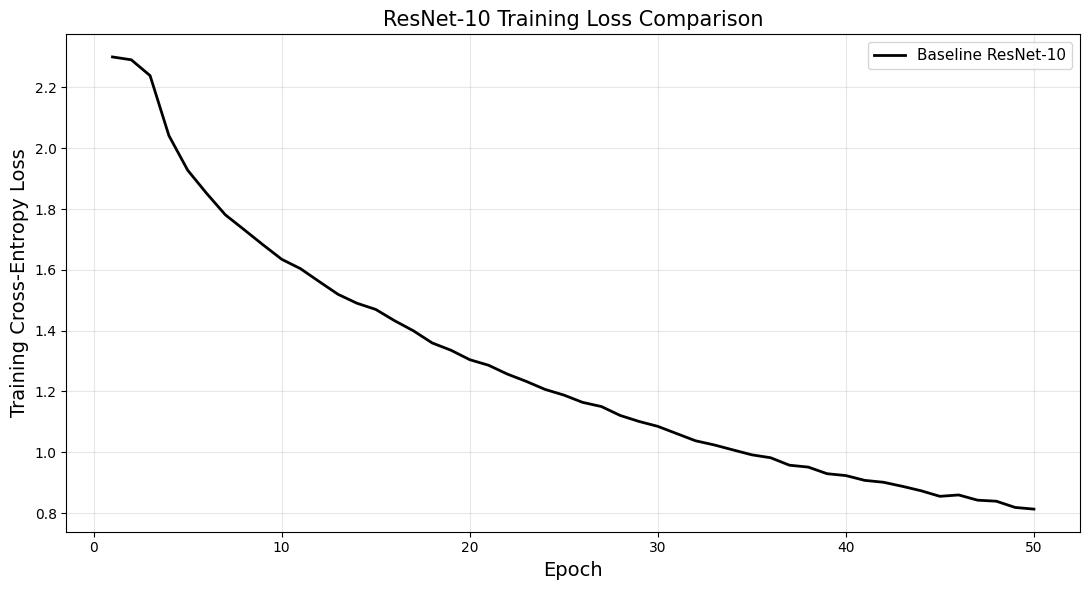

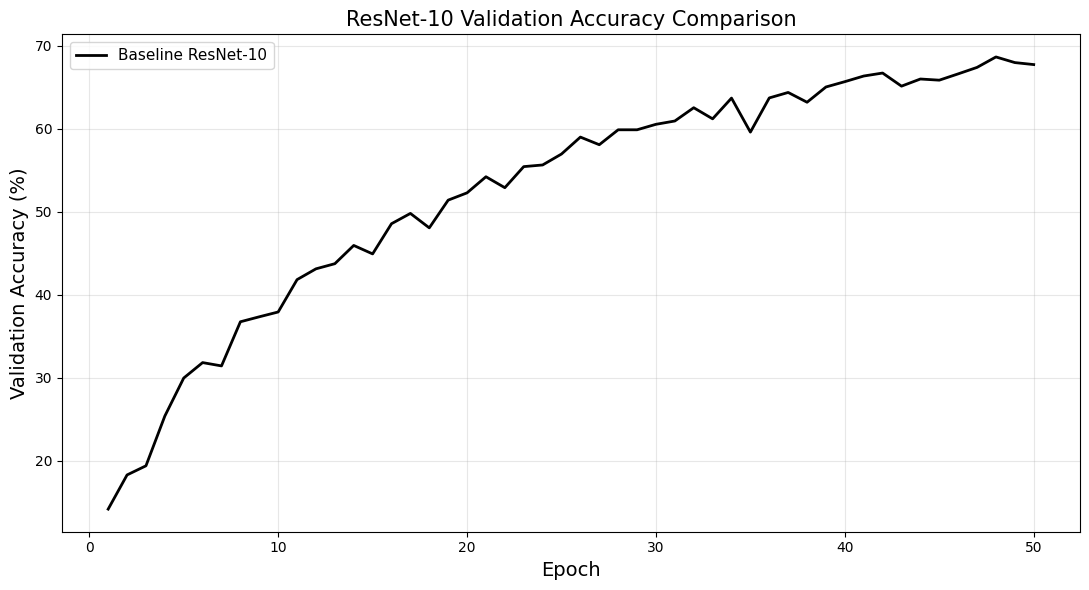


OVERALL MODEL COMPARISON


,Model,Epochs,GPU,Training Time (s),Training Time (min),Training Loss,Evaluation Accuracy (%),Parameters,Model Size (MiB)
0,Baseline CNN (1.a),300,Tesla T4,2930.830220,48.847170,0.439738,65.93,25578,0.097572
1,Extended CNN (1.b),300,"Tesla T4, CPU",4400.107621,73.335127,0.098686,68.26,33834,0.129066



CURRENT TRAINING BLOCK COMPLETED
Finished experiments: 0/4
Rerun the same cell to continue training.
All results saved to: /content/drive/MyDrive/ECGR5105_HW8/Problem_2

EXPERIMENT PROGRESS


,Experiment,Completed Epochs,Remaining Epochs,Progress (%),Final Results Saved
0,ResNet-10 Baseline,50,250,16.67,False
1,ResNet-10 Weight Decay,0,300,0.00,False
2,ResNet-10 Dropout,0,300,0.00,False
3,ResNet-10 Batch Normalization,0,300,0.00,False


In [ ]:
# ==============================================================
# ECGR 5105 - Introduction to Machine Learning
# Homework 8 - Problem 2(a) and Problem 2(b)
#
# CIFAR-10 Classification using ResNet-10
#
# Problem 2(a): Baseline ResNet-10
# Problem 2(b):
#     1. Weight Decay (lambda = 0.001)
#     2. Dropout (p = 0.3)
#     3. Batch Normalization
#
# Automatic CPU/GPU selection
# CPU fallback for recoverable CUDA errors
# Automatic checkpoint resumption
# Block-wise training
# ==============================================================

import os
import gc
import time
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from torch.utils.data import (
    DataLoader,
    TensorDataset,
    Subset
)

from google.colab import drive
from IPython.display import display


# ==============================================================
# 1. USER CONFIGURATION
# ==============================================================

# Hardware selection:
#
# "auto" : Try GPU first, otherwise use CPU
# "gpu"  : Prefer GPU, fallback to CPU if unavailable
# "cpu"  : Always use CPU

DEVICE_MODE = "auto"

# Experiment selection:
#
# "auto"          : First unfinished experiment
# "baseline"      : Problem 2(a)
# "weight_decay"  : Problem 2(b), weight decay
# "dropout"       : Problem 2(b), dropout
# "batch_norm"    : Problem 2(b), batch normalization
# "all"           : Run all unfinished experiments

EXPERIMENT = "auto"

# Total epochs required by homework

EPOCHS = 300

# Maximum additional epochs per experiment per execution.
# Set 300 to finish the selected experiment in one execution.
# Set 25 or 50 for smaller training blocks.

EPOCHS_PER_RUN = 50

SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 0.001
MOMENTUM = 0.9

WEIGHT_DECAY = 0.001
DROPOUT_P = 0.3

CPU_THREADS = min(4, os.cpu_count() or 2)

# Since CIFAR-10 is preloaded into RAM,
# multiprocessing DataLoader workers are not necessary.

NUM_WORKERS = 0

# Save a checkpoint after every epoch.

RESUME_TRAINING = True

assert DEVICE_MODE in ["auto", "gpu", "cpu"]
assert EPOCHS_PER_RUN > 0


# ==============================================================
# 2. Mount Google Drive
# ==============================================================

if not os.path.isdir("/content/drive/MyDrive"):

    drive.mount(
        "/content/drive",
        timeout_ms=120000
    )

DATA_DIR = "/content/drive/MyDrive/CIFAR10"

OUTPUT_DIR = "/content/drive/MyDrive/ECGR5105_HW8"

PROBLEM_2_DIR = os.path.join(
    OUTPUT_DIR,
    "Problem_2"
)

os.makedirs(PROBLEM_2_DIR, exist_ok=True)

if not os.path.isdir(
    os.path.join(DATA_DIR, "cifar-10-batches-py")
):

    raise FileNotFoundError(
        f"CIFAR-10 dataset not found in {DATA_DIR}"
    )


# ==============================================================
# 3. Experiment Definitions
# ==============================================================

EXPERIMENTS = {

    "baseline": {
        "name": "ResNet-10 Baseline",
        "weight_decay": 0.0,
        "dropout": 0.0,
        "batch_norm": False,
        "folder": "Problem_2a_Baseline"
    },

    "weight_decay": {
        "name": "ResNet-10 Weight Decay",
        "weight_decay": WEIGHT_DECAY,
        "dropout": 0.0,
        "batch_norm": False,
        "folder": "Problem_2b_Weight_Decay"
    },

    "dropout": {
        "name": "ResNet-10 Dropout",
        "weight_decay": 0.0,
        "dropout": DROPOUT_P,
        "batch_norm": False,
        "folder": "Problem_2b_Dropout"
    },

    "batch_norm": {
        "name": "ResNet-10 Batch Normalization",
        "weight_decay": 0.0,
        "dropout": 0.0,
        "batch_norm": True,
        "folder": "Problem_2b_Batch_Normalization"
    }
}

EXPERIMENT_ORDER = [
    "baseline",
    "weight_decay",
    "dropout",
    "batch_norm"
]

assert EXPERIMENT in (
    ["auto", "all"] + EXPERIMENT_ORDER
)

for config in EXPERIMENTS.values():

    os.makedirs(
        os.path.join(
            PROBLEM_2_DIR,
            config["folder"]
        ),
        exist_ok=True
    )


def experiment_dir(experiment_key):

    return os.path.join(
        PROBLEM_2_DIR,
        EXPERIMENTS[experiment_key]["folder"]
    )


def checkpoint_path(experiment_key):

    return os.path.join(
        experiment_dir(experiment_key),
        "checkpoint.pth"
    )


def results_path(experiment_key):

    return os.path.join(
        experiment_dir(experiment_key),
        "final_results.json"
    )


# ==============================================================
# 4. CPU/GPU Selection
# ==============================================================

def select_device():

    if DEVICE_MODE == "cpu":

        print("CPU mode selected.")

        return torch.device("cpu")

    try:

        if torch.cuda.is_available():

            # Test whether CUDA is actually usable.

            test_tensor = torch.zeros(
                1,
                device="cuda"
            )

            torch.cuda.synchronize()

            del test_tensor

            print(
                "GPU detected:",
                torch.cuda.get_device_name(0)
            )

            return torch.device("cuda")

        print("GPU unavailable. Switching to CPU.")

    except RuntimeError as error:

        print("GPU initialization failed.")
        print(error)
        print("Switching to CPU.")

    return torch.device("cpu")


def hardware_name(device):

    if device.type == "cuda":

        return torch.cuda.get_device_name(
            device.index or 0
        )

    return "CPU"


def synchronize_device(device):

    if device.type == "cuda":

        torch.cuda.synchronize()


def set_seed(seed, device):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if device.type == "cuda":

        torch.cuda.manual_seed_all(seed)


torch.set_num_threads(CPU_THREADS)

device = select_device()

if device.type == "cuda":

    torch.backends.cudnn.benchmark = True

set_seed(SEED, device)

print("\n" + "=" * 75)
print("HOMEWORK 8 - PROBLEM 2")
print("=" * 75)

print("Device:", device)
print("Hardware:", hardware_name(device))
print("Experiment:", EXPERIMENT)
print("Total epochs:", EPOCHS)
print("Epochs per execution:", EPOCHS_PER_RUN)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Momentum:", MOMENTUM)
print("CPU threads:", CPU_THREADS)
print("Output directory:", PROBLEM_2_DIR)


# ==============================================================
# 5. Load Existing CIFAR-10 Dataset
# ==============================================================

print("\nLoading CIFAR-10 from Google Drive...")

raw_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False
)

raw_test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=False
)

# Preprocess the entire dataset once.
#
# This avoids repeatedly converting PIL images to tensors
# and normalizing them during every training epoch.
#
# Normalization is identical to Problem 1:
#
# x_normalized = (x - 0.5) / 0.5


def preprocess_dataset(dataset):

    images = torch.from_numpy(dataset.data)

    # NHWC -> NCHW

    images = images.permute(
        0, 3, 1, 2
    ).contiguous()

    images = images.float()

    images.div_(255.0)

    images.sub_(0.5).div_(0.5)

    labels = torch.tensor(
        dataset.targets,
        dtype=torch.long
    )

    return TensorDataset(
        images,
        labels
    )


class_names = raw_train_dataset.classes

full_train_dataset = preprocess_dataset(
    raw_train_dataset
)

test_dataset = preprocess_dataset(
    raw_test_dataset
)

del raw_train_dataset
del raw_test_dataset

gc.collect()

# Preserve exactly the same 45,000 / 5,000 split
# used in Problem 1.

split_generator = torch.Generator().manual_seed(
    SEED
)

indices = torch.randperm(
    50000,
    generator=split_generator
).tolist()

train_indices = indices[:45000]

val_indices = indices[45000:]

train_dataset = Subset(
    full_train_dataset,
    train_indices
)

val_dataset = Subset(
    full_train_dataset,
    val_indices
)

print("\nDataset loaded successfully.")

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))
print("Number of classes:", len(class_names))
print("Classes:", class_names)

print("Dataset preprocessed and stored in RAM.")


# ==============================================================
# 6. Residual Block
# ==============================================================

class ResidualBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        stride=1,
        dropout=0.0,
        batch_norm=False
    ):

        super().__init__()

        # First convolution

        self.conv1 = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=not batch_norm
        )

        # Second convolution

        self.conv2 = nn.Conv2d(
            in_channels=out_channels,
            out_channels=out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=not batch_norm
        )

        # Batch normalization is enabled only
        # for the batch-normalization experiment.

        self.bn1 = (
            nn.BatchNorm2d(out_channels)
            if batch_norm
            else nn.Identity()
        )

        self.bn2 = (
            nn.BatchNorm2d(out_channels)
            if batch_norm
            else nn.Identity()
        )

        self.relu = nn.ReLU()

        # Dropout is enabled only for
        # the dropout experiment.

        self.dropout = (
            nn.Dropout(p=dropout)
            if dropout > 0
            else nn.Identity()
        )

        # Skip connection
        #
        # Identity when dimensions match.
        #
        # 1 x 1 convolution when dimensions differ.

        if (
            stride != 1
            or in_channels != out_channels
        ):

            shortcut_layers = [

                nn.Conv2d(
                    in_channels=in_channels,
                    out_channels=out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=not batch_norm
                )
            ]

            if batch_norm:

                shortcut_layers.append(
                    nn.BatchNorm2d(out_channels)
                )

            self.shortcut = nn.Sequential(
                *shortcut_layers
            )

        else:

            self.shortcut = nn.Identity()


    def forward(self, x):

        identity = self.shortcut(x)

        # Residual transformation F(x)

        out = self.conv1(x)

        out = self.bn1(out)

        out = self.relu(out)

        out = self.dropout(out)

        out = self.conv2(out)

        out = self.bn2(out)

        # Skip connection: F(x) + x

        out = out + identity

        out = self.relu(out)

        return out


# ==============================================================
# 7. ResNet-10 Architecture
# ==============================================================

class ResNet10(nn.Module):

    def __init__(
        self,
        num_classes=10,
        dropout=0.0,
        batch_norm=False
    ):

        super().__init__()

        self.in_channels = 16

        self.dropout_p = dropout

        self.use_batch_norm = batch_norm

        # ------------------------------------------------------
        # Initial convolution
        #
        # Input:  3 x 32 x 32
        # Output: 16 x 32 x 32
        # ------------------------------------------------------

        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=16,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=not batch_norm
        )

        self.bn1 = (
            nn.BatchNorm2d(16)
            if batch_norm
            else nn.Identity()
        )

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # After pooling: 16 x 16 x 16

        # ------------------------------------------------------
        # Stage 1: 3 residual blocks
        #
        # Output: 16 x 16 x 16
        # ------------------------------------------------------

        self.stage1 = self.make_stage(
            out_channels=16,
            num_blocks=3,
            first_stride=1
        )

        # ------------------------------------------------------
        # Stage 2: 3 residual blocks
        #
        # Output: 32 x 8 x 8
        # ------------------------------------------------------

        self.stage2 = self.make_stage(
            out_channels=32,
            num_blocks=3,
            first_stride=2
        )

        # ------------------------------------------------------
        # Stage 3: 4 residual blocks
        #
        # Output: 64 x 4 x 4
        # ------------------------------------------------------

        self.stage3 = self.make_stage(
            out_channels=64,
            num_blocks=4,
            first_stride=2
        )

        # Total residual blocks = 3 + 3 + 4 = 10

        # Global average pooling:
        # 64 x 4 x 4 -> 64 x 1 x 1

        self.avgpool = nn.AdaptiveAvgPool2d(
            (1, 1)
        )

        self.flatten = nn.Flatten()

        # CIFAR-10 contains 10 classes.

        self.fc = nn.Linear(
            64,
            num_classes
        )


    def make_stage(
        self,
        out_channels,
        num_blocks,
        first_stride
    ):

        layers = []

        for block_index in range(num_blocks):

            stride = (
                first_stride
                if block_index == 0
                else 1
            )

            layers.append(

                ResidualBlock(
                    in_channels=self.in_channels,
                    out_channels=out_channels,
                    stride=stride,
                    dropout=self.dropout_p,
                    batch_norm=self.use_batch_norm
                )

            )

            self.in_channels = out_channels

        return nn.Sequential(*layers)


    def forward(self, x):

        x = self.conv1(x)

        x = self.bn1(x)

        x = self.relu(x)

        x = self.pool(x)

        x = self.stage1(x)

        x = self.stage2(x)

        x = self.stage3(x)

        x = self.avgpool(x)

        x = self.flatten(x)

        x = self.fc(x)

        return x


# ==============================================================
# 8. Model Size
# ==============================================================

def count_parameters(model):

    return sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )


def model_size_mib(model):

    total_bytes = sum(

        parameter.numel()
        * parameter.element_size()

        for parameter in model.parameters()
    )

    return total_bytes / (1024 ** 2)


def count_residual_blocks(model):

    return sum(

        isinstance(module, ResidualBlock)

        for module in model.modules()
    )


# Verify the architecture.

verification_model = ResNet10()

with torch.no_grad():

    dummy_input = torch.zeros(
        2, 3, 32, 32
    )

    dummy_output = verification_model(
        dummy_input
    )

assert dummy_output.shape == (2, 10)

assert count_residual_blocks(
    verification_model
) == 10

print("\nResNet-10 architecture verified.")

print(
    "Residual blocks:",
    count_residual_blocks(verification_model)
)

print(
    "Baseline parameters:",
    count_parameters(verification_model)
)

print(
    "Output dimensions:",
    dummy_output.shape
)

del verification_model
del dummy_input
del dummy_output


# ==============================================================
# 9. DataLoaders
# ==============================================================

def create_loader(
    dataset,
    device,
    shuffle=False,
    seed=SEED
):

    generator = torch.Generator().manual_seed(
        seed
    )

    return DataLoader(

        dataset,

        batch_size=BATCH_SIZE,

        shuffle=shuffle,

        generator=generator,

        num_workers=NUM_WORKERS,

        pin_memory=device.type == "cuda",

        persistent_workers=NUM_WORKERS > 0

    )


# ==============================================================
# 10. Evaluation Function
# ==============================================================

def evaluate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0.0

    correct = 0

    total = 0

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=device.type == "cuda"
            )

            labels = labels.to(
                device,
                non_blocking=device.type == "cuda"
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            total_loss += (
                loss.item() * labels.size(0)
            )

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    return (

        total_loss / total,

        100.0 * correct / total

    )


# ==============================================================
# 11. Checkpoint Utility Functions
# ==============================================================

def load_checkpoint(experiment_key):

    path = checkpoint_path(
        experiment_key
    )

    if not os.path.exists(path):

        return None

    # Load only checkpoints generated by this notebook.

    return torch.load(

        path,

        map_location="cpu",

        weights_only=False

    )


def completed_epochs(experiment_key):

    checkpoint = load_checkpoint(
        experiment_key
    )

    if checkpoint is None:

        return 0

    return int(
        checkpoint["epoch"] + 1
    )


def save_checkpoint(
    checkpoint,
    experiment_key
):

    path = checkpoint_path(
        experiment_key
    )

    temporary_path = path + ".tmp"

    torch.save(

        checkpoint,

        temporary_path

    )

    os.replace(
        temporary_path,
        path
    )


def save_json(data, path):

    temporary_path = path + ".tmp"

    with open(temporary_path, "w") as file:

        json.dump(
            data,
            file,
            indent=4
        )

    os.replace(
        temporary_path,
        path
    )


# ==============================================================
# 12. Training Progress
# ==============================================================

def show_progress():

    progress = []

    for key in EXPERIMENT_ORDER:

        completed = completed_epochs(key)

        progress.append({

            "Experiment":
                EXPERIMENTS[key]["name"],

            "Completed Epochs":
                completed,

            "Remaining Epochs":
                max(0, EPOCHS - completed),

            "Progress (%)":
                100.0 * completed / EPOCHS,

            "Final Results Saved":
                os.path.exists(
                    results_path(key)
                )

        })

    progress_df = pd.DataFrame(progress)

    print("\n" + "=" * 75)

    print("EXPERIMENT PROGRESS")

    print("=" * 75)

    display(progress_df.round(2))

    progress_df.to_csv(

        os.path.join(
            PROBLEM_2_DIR,
            "training_progress.csv"
        ),

        index=False

    )


show_progress()


# ==============================================================
# 13. Save Training History
# ==============================================================

def save_training_history(
    history,
    experiment_key
):

    history_df = pd.DataFrame(history)

    history_df.insert(

        0,

        "Epoch",

        np.arange(
            1,
            len(history_df) + 1
        )

    )

    history_df.to_csv(

        os.path.join(
            experiment_dir(experiment_key),
            "training_history.csv"
        ),

        index=False

    )


# ==============================================================
# 14. Main Training Function
# ==============================================================

def train_experiment(
    experiment_key,
    device,
    target_epoch
):

    config = EXPERIMENTS[
        experiment_key
    ]

    model_name = config["name"]

    save_dir = experiment_dir(
        experiment_key
    )

    current_hardware = hardware_name(
        device
    )

    set_seed(SEED, device)

    # Initialize an independent ResNet-10 model.

    model = ResNet10(

        num_classes=10,

        dropout=config["dropout"],

        batch_norm=config["batch_norm"]

    ).to(device)

    criterion = nn.CrossEntropyLoss()

    # Weight decay is nonzero only for
    # the weight-decay experiment.

    optimizer = optim.SGD(

        model.parameters(),

        lr=LEARNING_RATE,

        momentum=MOMENTUM,

        weight_decay=config["weight_decay"]

    )

    configuration = {

        "architecture":
            "ResNet10_16_32_64_3_3_4_v1",

        "experiment":
            experiment_key,

        "total_epochs":
            EPOCHS,

        "batch_size":
            BATCH_SIZE,

        "learning_rate":
            LEARNING_RATE,

        "momentum":
            MOMENTUM,

        "weight_decay":
            config["weight_decay"],

        "dropout":
            config["dropout"],

        "batch_norm":
            config["batch_norm"],

        "seed":
            SEED

    }

    history = {

        "train_loss": [],

        "train_accuracy": [],

        "val_loss": [],

        "val_accuracy": [],

        "epoch_time": [],

        "hardware": []

    }

    start_epoch = 0

    total_training_time = 0.0

    # ----------------------------------------------------------
    # Resume existing training
    # ----------------------------------------------------------

    checkpoint = (

        load_checkpoint(experiment_key)

        if RESUME_TRAINING

        else None

    )

    if checkpoint is not None:

        if (
            checkpoint["configuration"]
            != configuration
        ):

            raise ValueError(

                "Checkpoint configuration mismatch. "
                "Do not overwrite the existing checkpoint."

            )

        model.load_state_dict(

            checkpoint["model_state_dict"]

        )

        optimizer.load_state_dict(

            checkpoint["optimizer_state_dict"]

        )

        # Move optimizer state to the current hardware.

        for state in optimizer.state.values():

            for key, value in state.items():

                if torch.is_tensor(value):

                    state[key] = value.to(
                        device
                    )

        start_epoch = (

            checkpoint["epoch"] + 1

        )

        history = checkpoint["history"]

        total_training_time = checkpoint[
            "total_training_time"
        ]

        print(
            f"\nCheckpoint loaded: {model_name}"
        )

        print(
            "Completed epochs:",
            start_epoch
        )

        print(
            "Remaining epochs:",
            EPOCHS - start_epoch
        )

        print(
            "Previous training time:",
            f"{total_training_time / 60:.2f} min"
        )

    elif os.path.exists(
        results_path(experiment_key)
    ):

        raise RuntimeError(

            "Final results exist but the checkpoint "
            "is missing. Check saved files before retraining."

        )

    # Skip experiments that are already completed.

    if (

        start_epoch >= EPOCHS

        and os.path.exists(
            results_path(experiment_key)
        )

    ):

        print(
            f"\n{model_name} already completed."
        )

        with open(

            results_path(experiment_key),

            "r"

        ) as file:

            return json.load(file)

    parameters = count_parameters(model)

    size_mib = model_size_mib(model)

    print("\n" + "=" * 75)

    print("MODEL:", model_name)

    print("=" * 75)

    print("Hardware:", current_hardware)

    print(
        "Residual blocks:",
        count_residual_blocks(model)
    )

    print(
        "Trainable parameters:",
        f"{parameters:,}"
    )

    print(
        "Model size:",
        f"{size_mib:.6f} MiB"
    )

    print(
        "Weight decay:",
        config["weight_decay"]
    )

    print(
        "Dropout:",
        config["dropout"]
    )

    print(
        "Batch normalization:",
        config["batch_norm"]
    )

    target_epoch = min(
        target_epoch,
        EPOCHS
    )

    if start_epoch < target_epoch:

        print(

            f"Training epochs "
            f"{start_epoch + 1} to "
            f"{target_epoch}"

        )

    val_loader = create_loader(

        val_dataset,

        device,

        shuffle=False

    )

    # ----------------------------------------------------------
    # Training loop
    # ----------------------------------------------------------

    for epoch in range(
        start_epoch,
        target_epoch
    ):

        # Deterministic epoch-specific seed.
        # This preserves the epoch's data order
        # across runtime interruptions.

        set_seed(
            SEED + epoch,
            device
        )

        train_loader = create_loader(

            train_dataset,

            device,

            shuffle=True,

            seed=SEED + epoch

        )

        model.train()

        running_loss = 0.0

        correct = 0

        total = 0

        synchronize_device(device)

        epoch_start = time.perf_counter()

        for images, labels in train_loader:

            images = images.to(

                device,

                non_blocking=device.type == "cuda"

            )

            labels = labels.to(

                device,

                non_blocking=device.type == "cuda"

            )

            # Clear previous gradients.

            optimizer.zero_grad(
                set_to_none=True
            )

            # Forward propagation.

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            # Backpropagation.

            loss.backward()

            # Parameter update.

            optimizer.step()

            # Training statistics.

            running_loss += (

                loss.item() * labels.size(0)

            )

            predictions = outputs.argmax(
                dim=1
            )

            correct += (

                predictions == labels

            ).sum().item()

            total += labels.size(0)

        synchronize_device(device)

        epoch_time = (

            time.perf_counter() - epoch_start

        )

        total_training_time += epoch_time

        train_loss = running_loss / total

        train_accuracy = (

            100.0 * correct / total

        )

        # Validation performance.

        val_loss, val_accuracy = evaluate(

            model,

            val_loader,

            criterion,

            device

        )

        history["train_loss"].append(
            train_loss
        )

        history["train_accuracy"].append(
            train_accuracy
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_accuracy"].append(
            val_accuracy
        )

        history["epoch_time"].append(
            epoch_time
        )

        history["hardware"].append(
            current_hardware
        )

        # ------------------------------------------------------
        # Save checkpoint after every completed epoch.
        # ------------------------------------------------------

        checkpoint = {

            "epoch":
                epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "history":
                history,

            "total_training_time":
                total_training_time,

            "configuration":
                configuration

        }

        save_checkpoint(

            checkpoint,

            experiment_key

        )

        save_training_history(

            history,

            experiment_key

        )

        # Estimate remaining training time
        # based on the latest epoch duration.

        remaining_epochs = (

            EPOCHS - (epoch + 1)

        )

        remaining_minutes = (

            remaining_epochs
            * epoch_time / 60

        )

        block_remaining = (

            target_epoch - (epoch + 1)

        )

        block_remaining_minutes = (

            block_remaining
            * epoch_time / 60

        )

        print(

            f"Epoch [{epoch + 1:3d}/{EPOCHS}] | "

            f"Train Loss: {train_loss:.4f} | "

            f"Train Acc: {train_accuracy:.2f}% | "

            f"Val Loss: {val_loss:.4f} | "

            f"Val Acc: {val_accuracy:.2f}% | "

            f"Time: {epoch_time:.2f}s | "

            f"Block ETA: "
            f"{block_remaining_minutes:.1f}min | "

            f"Total ETA: "
            f"{remaining_minutes:.1f}min | "

            f"{current_hardware}",

            flush=True

        )

    # ----------------------------------------------------------
    # Stop safely when the current training block finishes.
    # ----------------------------------------------------------

    trained_epochs = len(
        history["train_loss"]
    )

    if trained_epochs < EPOCHS:

        print("\n" + "=" * 75)

        print("TRAINING BLOCK COMPLETED")

        print("=" * 75)

        print("Model:", model_name)

        print(

            f"Progress: "
            f"{trained_epochs}/{EPOCHS} epochs"

        )

        print(

            f"Remaining epochs: "
            f"{EPOCHS - trained_epochs}"

        )

        print("Checkpoint saved successfully.")

        print(
            "Rerun this cell to continue training."
        )

        # Do not evaluate on the test dataset
        # until all 300 epochs are completed.

        return None

    # ----------------------------------------------------------
    # Final testing after exactly 300 epochs
    # ----------------------------------------------------------

    print(

        "\nEvaluating final model "
        "on the test dataset..."

    )

    test_loader = create_loader(

        test_dataset,

        device,

        shuffle=False

    )

    test_loss, test_accuracy = evaluate(

        model,

        test_loader,

        criterion,

        device

    )

    hardware_used = list(

        dict.fromkeys(
            history["hardware"]
        )

    )

    # Track training time and epoch counts
    # separately for CPU and GPU.

    hardware_summary = {}

    for hardware, seconds in zip(

        history["hardware"],

        history["epoch_time"]

    ):

        if hardware not in hardware_summary:

            hardware_summary[hardware] = {

                "Epochs": 0,

                "Training Time (s)": 0.0

            }

        hardware_summary[hardware][
            "Epochs"
        ] += 1

        hardware_summary[hardware][
            "Training Time (s)"
        ] += float(seconds)

    results = {

        "Model":
            model_name,

        "Epochs":
            EPOCHS,

        "Residual Blocks":
            count_residual_blocks(model),

        "GPU":
            ", ".join(hardware_used),

        "Evaluation Device":
            current_hardware,

        "Weight Decay":
            config["weight_decay"],

        "Dropout":
            config["dropout"],

        "Batch Normalization":
            config["batch_norm"],

        "Training Time (s)":
            total_training_time,

        "Training Time (min)":
            total_training_time / 60,

        "Training Time per Epoch (s)":
            total_training_time / EPOCHS,

        "Training Loss":
            history["train_loss"][-1],

        "Training Accuracy (%)":
            history["train_accuracy"][-1],

        "Validation Loss":
            history["val_loss"][-1],

        "Validation Accuracy (%)":
            history["val_accuracy"][-1],

        "Test Loss":
            test_loss,

        "Evaluation Accuracy (%)":
            test_accuracy,

        "Parameters":
            parameters,

        "Model Size (MiB)":
            size_mib,

        "Hardware Breakdown":
            hardware_summary

    }

    # Save the final model in CPU-compatible format.

    cpu_state_dict = {

        key: value.detach().cpu()

        for key, value
        in model.state_dict().items()

    }

    torch.save(

        cpu_state_dict,

        os.path.join(
            save_dir,
            "final_model.pth"
        )

    )

    save_json(

        results,

        results_path(experiment_key)

    )

    save_training_history(

        history,

        experiment_key

    )

    print("\n" + "=" * 75)

    print("FINAL RESULTS:", model_name)

    print("=" * 75)

    for key, value in results.items():

        if isinstance(value, float):

            print(
                f"{key}: {value:.6f}"
            )

        else:

            print(
                f"{key}: {value}"
            )

    return results


# ==============================================================
# 15. Automatic GPU-to-CPU Fallback
# ==============================================================

def is_cuda_error(error):

    message = str(error).lower()

    cuda_error_keywords = [

        "cuda",

        "cudnn",

        "cublas",

        "device-side assert",

        "out of memory",

        "driver shutting down"

    ]

    return any(

        keyword in message

        for keyword in cuda_error_keywords

    )


def run_with_fallback(
    experiment_key,
    device
):

    start = completed_epochs(
        experiment_key
    )

    # Preserve the target epoch if GPU fails.
    # CPU continues the same training block.

    target = min(

        start + EPOCHS_PER_RUN,

        EPOCHS

    )

    try:

        result = train_experiment(

            experiment_key,

            device,

            target

        )

        return result, device

    except RuntimeError as error:

        if (

            device.type != "cuda"

            or not is_cuda_error(error)

        ):

            raise

        # A recoverable CUDA-related failure occurred.

        print("\n" + "=" * 75)

        print("GPU TRAINING FAILED")

        print("=" * 75)

        print(error)

        print(

            "Switching to CPU and resuming "
            "from the last saved checkpoint."

        )

    # Release failed GPU allocations.

    gc.collect()

    try:

        torch.cuda.empty_cache()

    except RuntimeError:

        pass

    device = torch.device("cpu")

    torch.set_num_threads(
        CPU_THREADS
    )

    result = train_experiment(

        experiment_key,

        device,

        target

    )

    return result, device


# ==============================================================
# 16. Select Experiments to Train
# ==============================================================

unfinished_experiments = [

    key

    for key in EXPERIMENT_ORDER

    if (

        completed_epochs(key) < EPOCHS

        or not os.path.exists(
            results_path(key)
        )

    )

]

if EXPERIMENT == "auto":

    selected_experiments = (

        unfinished_experiments[:1]

    )

elif EXPERIMENT == "all":

    selected_experiments = (

        unfinished_experiments

    )

else:

    selected_experiments = [

        EXPERIMENT

    ]


# ==============================================================
# 17. Execute Selected Experiments
# ==============================================================

if not selected_experiments:

    print(

        "\nAll ResNet-10 experiments "
        "have already completed."

    )

for experiment_key in selected_experiments:

    print("\n" + "=" * 75)

    print(

        "SELECTED EXPERIMENT:",

        EXPERIMENTS[
            experiment_key
        ]["name"]

    )

    print("=" * 75)

    result, device = run_with_fallback(

        experiment_key,

        device

    )

    gc.collect()

    if device.type == "cuda":

        torch.cuda.empty_cache()

show_progress()


# ==============================================================
# 18. Load Actual Problem 1 Results
# ==============================================================

baseline_cnn_path = os.path.join(

    OUTPUT_DIR,

    "Problem_1a",

    "final_results.json"

)

extended_cnn_path = os.path.join(

    OUTPUT_DIR,

    "Problem_1b",

    "final_results.json"

)

if os.path.exists(baseline_cnn_path):

    with open(

        baseline_cnn_path,

        "r"

    ) as file:

        baseline_cnn_results = json.load(
            file
        )

else:

    # Actual results from completed Problem 1(a).

    baseline_cnn_results = {

        "Model": "Baseline CNN (1.a)",

        "Epochs": 300,

        "GPU": "Tesla T4",

        "Training Time (s)": 2930.830220,

        "Training Time (min)": 48.847170,

        "Training Loss": 0.439738,

        "Training Accuracy (%)": 84.704444,

        "Validation Accuracy (%)": 65.64,

        "Evaluation Accuracy (%)": 65.93,

        "Parameters": 25578,

        "Model Size (MiB)": 0.097572

    }

if os.path.exists(extended_cnn_path):

    with open(

        extended_cnn_path,

        "r"

    ) as file:

        extended_cnn_results = json.load(
            file
        )

else:

    # Actual results from completed Problem 1(b).

    extended_cnn_results = {

        "Model": "Extended CNN (1.b)",

        "Epochs": 300,

        "GPU": "Tesla T4, CPU",

        "Training Time (s)": 4400.107621,

        "Training Time (min)": 73.335127,

        "Training Loss": 0.098686,

        "Training Accuracy (%)": 96.775556,

        "Validation Accuracy (%)": 68.44,

        "Evaluation Accuracy (%)": 68.26,

        "Parameters": 33834,

        "Model Size (MiB)": 0.129066

    }


# ==============================================================
# 19. Load Completed ResNet Results
# ==============================================================

resnet_results = {}

resnet_histories = {}

for key in EXPERIMENT_ORDER:

    path = results_path(key)

    if os.path.exists(path):

        with open(path, "r") as file:

            saved_results = json.load(
                file
            )

        if saved_results["Epochs"] == EPOCHS:

            resnet_results[key] = saved_results

    checkpoint = load_checkpoint(key)

    if checkpoint is not None:

        resnet_histories[key] = (

            checkpoint["history"]

        )


# ==============================================================
# 20. Problem 2(a): ResNet versus Extended CNN
# ==============================================================

comparison_columns = [

    "Model",

    "Epochs",

    "GPU",

    "Training Time (s)",

    "Training Time (min)",

    "Training Loss",

    "Evaluation Accuracy (%)",

    "Parameters",

    "Model Size (MiB)"

]

if "baseline" in resnet_results:

    baseline_resnet = resnet_results[
        "baseline"
    ]

    comparison_2a = pd.DataFrame([

        extended_cnn_results,

        baseline_resnet

    ])[comparison_columns]

    print("\n" + "=" * 75)

    print(
        "PROBLEM 2(a): "
        "RESNET-10 VS EXTENDED CNN"
    )

    print("=" * 75)

    display(
        comparison_2a.round(6)
    )

    comparison_2a.to_csv(

        os.path.join(

            PROBLEM_2_DIR,

            "Problem_2a_Comparison.csv"

        ),

        index=False

    )

    accuracy_difference = (

        baseline_resnet[
            "Evaluation Accuracy (%)"
        ]

        - extended_cnn_results[
            "Evaluation Accuracy (%)"
        ]

    )

    parameter_change = 100.0 * (

        baseline_resnet["Parameters"]

        - extended_cnn_results["Parameters"]

    ) / extended_cnn_results["Parameters"]

    time_change = 100.0 * (

        baseline_resnet["Training Time (s)"]

        - extended_cnn_results[
            "Training Time (s)"
        ]

    ) / extended_cnn_results[
        "Training Time (s)"
    ]

    print(

        f"Accuracy difference: "

        f"{accuracy_difference:+.2f} "

        "percentage points"

    )

    print(

        f"Parameter change: "

        f"{parameter_change:+.2f}%"

    )

    print(

        f"Training time change: "

        f"{time_change:+.2f}%"

    )

    if (

        baseline_resnet["GPU"]

        != extended_cnn_results["GPU"]

    ):

        print(

            "NOTE: Training hardware differs. "

            "Training time differences cannot be "

            "attributed solely to model architecture."

        )


# ==============================================================
# 21. Problem 2(b): Regularization Comparison
# ==============================================================

regularization_keys = [

    "weight_decay",

    "dropout",

    "batch_norm"

]

completed_regularization = [

    resnet_results[key]

    for key in regularization_keys

    if key in resnet_results

]

if completed_regularization:

    comparison_rows = [

        baseline_cnn_results

    ]

    if "baseline" in resnet_results:

        comparison_rows.append(

            resnet_results["baseline"]

        )

    comparison_rows.extend(

        completed_regularization

    )

    comparison_2b = pd.DataFrame(

        comparison_rows

    )[comparison_columns]

    print("\n" + "=" * 75)

    print(

        "PROBLEM 2(b): "

        "REGULARIZATION COMPARISON"

    )

    print("=" * 75)

    display(

        comparison_2b.round(6)

    )

    comparison_2b.to_csv(

        os.path.join(

            PROBLEM_2_DIR,

            "Problem_2b_Comparison.csv"

        ),

        index=False

    )

    regularization_analysis = []

    for result in completed_regularization:

        accuracy_difference_cnn = (

            result["Evaluation Accuracy (%)"]

            - baseline_cnn_results[
                "Evaluation Accuracy (%)"
            ]

        )

        time_difference_cnn = 100.0 * (

            result["Training Time (s)"]

            - baseline_cnn_results[
                "Training Time (s)"
            ]

        ) / baseline_cnn_results[
            "Training Time (s)"
        ]

        analysis = {

            "Model":
                result["Model"],

            "Accuracy Difference vs CNN (pp)":
                accuracy_difference_cnn,

            "Training Time Change vs CNN (%)":
                time_difference_cnn,

            "Training Hardware":
                result["GPU"]

        }

        if "baseline" in resnet_results:

            baseline_resnet = resnet_results[
                "baseline"
            ]

            analysis[
                "Accuracy Difference vs Baseline ResNet (pp)"
            ] = (

                result["Evaluation Accuracy (%)"]

                - baseline_resnet[
                    "Evaluation Accuracy (%)"
                ]

            )

            analysis[
                "Training Time Change vs Baseline ResNet (%)"
            ] = 100.0 * (

                result["Training Time (s)"]

                - baseline_resnet[
                    "Training Time (s)"
                ]

            ) / baseline_resnet[
                "Training Time (s)"
            ]

        regularization_analysis.append(
            analysis
        )

    analysis_df = pd.DataFrame(
        regularization_analysis
    )

    print("\nRegularization analysis:")

    display(
        analysis_df.round(4)
    )

    analysis_df.to_csv(

        os.path.join(

            PROBLEM_2_DIR,

            "Problem_2b_Regularization_Analysis.csv"

        ),

        index=False

    )


# ==============================================================
# 22. Training Loss Comparison
# ==============================================================

plot_labels = {

    "baseline":
        "Baseline ResNet-10",

    "weight_decay":
        "Weight Decay (0.001)",

    "dropout":
        "Dropout (0.3)",

    "batch_norm":
        "Batch Normalization"

}

plot_colors = {

    "baseline": "black",

    "weight_decay": "blue",

    "dropout": "red",

    "batch_norm": "green"

}

if resnet_histories:

    plt.figure(figsize=(11, 6))

    for key, history in resnet_histories.items():

        epochs = np.arange(

            1,

            len(history["train_loss"]) + 1

        )

        plt.plot(

            epochs,

            history["train_loss"],

            label=plot_labels[key],

            color=plot_colors[key],

            linewidth=2

        )

    plt.xlabel("Epoch", fontsize=14)

    plt.ylabel(
        "Training Cross-Entropy Loss",
        fontsize=14
    )

    plt.title(
        "ResNet-10 Training Loss Comparison",
        fontsize=15
    )

    plt.legend(fontsize=11)

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            PROBLEM_2_DIR,

            "Problem_2_Training_Loss.png"

        ),

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()

    plt.close()


# ==============================================================
# 23. Validation Accuracy Comparison
# ==============================================================

if resnet_histories:

    plt.figure(figsize=(11, 6))

    for key, history in resnet_histories.items():

        epochs = np.arange(

            1,

            len(history["val_accuracy"]) + 1

        )

        plt.plot(

            epochs,

            history["val_accuracy"],

            label=plot_labels[key],

            color=plot_colors[key],

            linewidth=2

        )

    plt.xlabel("Epoch", fontsize=14)

    plt.ylabel(
        "Validation Accuracy (%)",
        fontsize=14
    )

    plt.title(

        "ResNet-10 Validation Accuracy Comparison",

        fontsize=15

    )

    plt.legend(fontsize=11)

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            PROBLEM_2_DIR,

            "Problem_2_Validation_Accuracy.png"

        ),

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()

    plt.close()


# ==============================================================
# 24. Training versus Validation Performance
# ==============================================================

for key, history in resnet_histories.items():

    epochs = np.arange(

        1,

        len(history["train_loss"]) + 1

    )

    save_dir = experiment_dir(key)

    # Loss comparison.

    plt.figure(figsize=(9, 5))

    plt.plot(

        epochs,

        history["train_loss"],

        label="Training Loss",

        linewidth=2

    )

    plt.plot(

        epochs,

        history["val_loss"],

        label="Validation Loss",

        linestyle="--",

        linewidth=2

    )

    plt.xlabel("Epoch", fontsize=13)

    plt.ylabel(
        "Cross-Entropy Loss",
        fontsize=13
    )

    plt.title(

        plot_labels[key] + " - Loss",

        fontsize=14

    )

    plt.legend()

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(

        os.path.join(
            save_dir,
            "loss_curve.png"
        ),

        dpi=300,

        bbox_inches="tight"

    )

    plt.close()

    # Accuracy comparison.

    plt.figure(figsize=(9, 5))

    plt.plot(

        epochs,

        history["train_accuracy"],

        label="Training Accuracy",

        linewidth=2

    )

    plt.plot(

        epochs,

        history["val_accuracy"],

        label="Validation Accuracy",

        linestyle="--",

        linewidth=2

    )

    plt.xlabel("Epoch", fontsize=13)

    plt.ylabel("Accuracy (%)", fontsize=13)

    plt.title(

        plot_labels[key] + " - Accuracy",

        fontsize=14

    )

    plt.legend()

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(

        os.path.join(
            save_dir,
            "accuracy_curve.png"
        ),

        dpi=300,

        bbox_inches="tight"

    )

    plt.close()


# ==============================================================
# 25. Overfitting Analysis
# ==============================================================

overfitting_results = []

for key, results in resnet_results.items():

    history = resnet_histories.get(
        key
    )

    if history is None:

        continue

    train_accuracy = results[
        "Training Accuracy (%)"
    ]

    val_accuracy = results[
        "Validation Accuracy (%)"
    ]

    generalization_gap = (

        train_accuracy - val_accuracy

    )

    minimum_val_loss = min(

        history["val_loss"]

    )

    final_val_loss = history[
        "val_loss"
    ][-1]

    best_epoch = int(

        np.argmin(
            history["val_loss"]
        ) + 1

    )

    overfitting_results.append({

        "Model":
            results["Model"],

        "Training Accuracy (%)":
            train_accuracy,

        "Validation Accuracy (%)":
            val_accuracy,

        "Evaluation Accuracy (%)":
            results["Evaluation Accuracy (%)"],

        "Generalization Gap (pp)":
            generalization_gap,

        "Minimum Validation Loss":
            minimum_val_loss,

        "Minimum Validation Loss Epoch":
            best_epoch,

        "Final Validation Loss":
            final_val_loss,

        "Validation Loss Increase":
            final_val_loss - minimum_val_loss

    })

if overfitting_results:

    overfitting_df = pd.DataFrame(

        overfitting_results

    )

    print("\n" + "=" * 75)

    print("OVERFITTING ANALYSIS")

    print("=" * 75)

    display(

        overfitting_df.round(4)

    )

    overfitting_df.to_csv(

        os.path.join(

            PROBLEM_2_DIR,

            "Problem_2_Overfitting_Analysis.csv"

        ),

        index=False

    )


# ==============================================================
# 26. Final Comparison Across All Models
# ==============================================================

all_results = [

    baseline_cnn_results,

    extended_cnn_results

]

for key in EXPERIMENT_ORDER:

    if key in resnet_results:

        all_results.append(

            resnet_results[key]

        )

all_comparison = pd.DataFrame(

    all_results

)[comparison_columns]

print("\n" + "=" * 75)

print("OVERALL MODEL COMPARISON")

print("=" * 75)

display(

    all_comparison.round(6)

)

all_comparison.to_csv(

    os.path.join(

        PROBLEM_2_DIR,

        "Homework_8_Model_Comparison.csv"

    ),

    index=False

)


# ==============================================================
# 27. Final Accuracy Bar Chart
# ==============================================================

if resnet_results:

    labels = [

        result["Model"]

        for result in all_results

    ]

    accuracies = [

        result["Evaluation Accuracy (%)"]

        for result in all_results

    ]

    plt.figure(figsize=(12, 6))

    bars = plt.bar(

        labels,

        accuracies

    )

    for bar, accuracy in zip(

        bars,

        accuracies

    ):

        plt.text(

            bar.get_x() + bar.get_width() / 2,

            accuracy + 1,

            f"{accuracy:.2f}%",

            ha="center",

            fontsize=11

        )

    plt.ylabel(
        "Evaluation Accuracy (%)",
        fontsize=14
    )

    plt.title(

        "Homework 8 - Evaluation Accuracy Comparison",

        fontsize=15

    )

    plt.ylim(0, 105)

    plt.xticks(

        rotation=25,

        ha="right"

    )

    plt.grid(

        axis="y",

        alpha=0.3

    )

    plt.tight_layout()

    plt.savefig(

        os.path.join(

            PROBLEM_2_DIR,

            "Homework_8_Accuracy_Comparison.png"

        ),

        dpi=300,

        bbox_inches="tight"

    )

    plt.show()

    plt.close()


# ==============================================================
# 28. Save Final Summary
# ==============================================================

summary = {

    "Problem_1a_Baseline_CNN":
        baseline_cnn_results,

    "Problem_1b_Extended_CNN":
        extended_cnn_results,

    "Problem_2_Completed_Experiments":
        resnet_results,

    "Overfitting_Analysis":
        overfitting_results,

    "Training_Time_Definition":

        "Training time includes completed training epochs "
        "and excludes validation, testing, checkpoint saving, "
        "and incomplete epochs lost during interruptions.",

    "Training_Time_Limitation":

        "CPU and GPU training times may not be directly "
        "comparable because the hardware differs.",

    "All_Experiments_Completed":

        len(resnet_results) == len(EXPERIMENT_ORDER)

}

save_json(

    summary,

    os.path.join(

        PROBLEM_2_DIR,

        "Problem_2_Final_Summary.json"

    )

)


# ==============================================================
# 29. Completion Status
# ==============================================================

print("\n" + "=" * 75)

if len(resnet_results) == 4:

    print(

        "HOMEWORK 8 - PROBLEM 2 COMPLETED"

    )

    print(

        "All four ResNet-10 experiments "
        "completed 300 epochs."

    )

else:

    print(

        "CURRENT TRAINING BLOCK COMPLETED"

    )

    print(

        f"Finished experiments: "

        f"{len(resnet_results)}/4"

    )

    print(

        "Rerun the same cell to continue training."

    )

print("=" * 75)

print(

    "All results saved to:",

    PROBLEM_2_DIR

)

show_progress()

GPU detected: Tesla T4

HOMEWORK 8 - PROBLEM 2
Device: cuda
Hardware: Tesla T4
Experiment: all
Total epochs: 300
Epochs per execution: 300
Batch size: 128
Learning rate: 0.001
Momentum: 0.9
CPU threads: 2
Dataset directory: /content/drive/MyDrive/CIFAR10
Output directory: /content/drive/MyDrive/ECGR5105_HW8/Problem_2

Loading CIFAR-10 from Google Drive...

Dataset loaded successfully.
Training samples: 45000
Validation samples: 5000
Testing samples: 10000
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Dataset preprocessed and stored in RAM.

ResNet-10 architecture verified.
Residual blocks: 10
Baseline parameters: 345546
Output dimensions: torch.Size([2, 10])

EXPERIMENT PROGRESS


,Experiment,Completed Epochs,Remaining Epochs,Progress (%),Final Results Saved
0,ResNet-10 Baseline,50,250,16.67,False
1,ResNet-10 Weight Decay,0,300,0.00,False
2,ResNet-10 Dropout,0,300,0.00,False
3,ResNet-10 Batch Normalization,0,300,0.00,False


Overall progress: 50/1200 epochs (4.17%)

Problem 1 results loaded successfully.

EXPERIMENTS TO RUN
1. ResNet-10 Baseline | Completed: 50/300 | Remaining: 250
2. ResNet-10 Weight Decay | Completed: 0/300 | Remaining: 300
3. ResNet-10 Dropout | Completed: 0/300 | Remaining: 300
4. ResNet-10 Batch Normalization | Completed: 0/300 | Remaining: 300

SELECTED EXPERIMENT: ResNet-10 Baseline

Checkpoint loaded: ResNet-10 Baseline
Completed epochs: 50
Remaining epochs: 250
Previous training time: 3.57 min

MODEL: ResNet-10 Baseline
Hardware: Tesla T4
Residual blocks: 10
Trainable parameters: 345,546
Model size: 1.318153 MiB
Weight decay: 0.0
Dropout: 0.0
Batch normalization: False
Training epochs 51 to 300
Epoch [ 51/300] | Train Loss: 0.8095 | Train Acc: 71.18% | Val Loss: 0.8694 | Val Acc: 68.90% | Time: 3.65s | Remaining: 16.5min | Tesla T4
Epoch [ 52/300] | Train Loss: 0.7967 | Train Acc: 71.63% | Val Loss: 0.8440 | Val Acc: 69.82% | Time: 5.50s | Remaining: 18.0min | Tesla T4
Epoch [ 53/

,Experiment,Completed Epochs,Remaining Epochs,Progress (%),Final Results Saved
0,ResNet-10 Baseline,300,0,100.0,True
1,ResNet-10 Weight Decay,0,300,0.0,False
2,ResNet-10 Dropout,0,300,0.0,False
3,ResNet-10 Batch Normalization,0,300,0.0,False


Overall progress: 300/1200 epochs (25.00%)

PROBLEM 2(a): RESNET-10 VS EXTENDED CNN


,Model,Epochs,GPU,Training Time (s),Training Time (min),Training Loss,Evaluation Accuracy (%),Parameters,Model Size (MiB)
0,Extended CNN (1.b),300,"Tesla T4, CPU",4400.107621,73.335127,0.098686,68.26,33834,0.129066
1,ResNet-10 Baseline,300,Tesla T4,1292.340809,21.539013,0.000010,72.37,345546,1.318153


... (44 outputs left out)


PROBLEM 2(b): REGULARIZATION ANALYSIS


,Model,Accuracy Difference vs CNN (pp),Training Time Change vs CNN (%),Training Hardware,Accuracy Difference vs Baseline ResNet (pp),Training Loss Difference vs Baseline ResNet,Training Time Change vs Baseline ResNet (%)
0,ResNet-10 Weight Decay,7.10,-56.052426,Tesla T4,0.66,0.000496,-0.333661
1,ResNet-10 Dropout,13.71,-52.000160,Tesla T4,7.27,0.282972,8.856256
2,ResNet-10 Batch Normalization,2.63,-42.446035,Tesla T4,-3.81,0.000097,30.523541



OVERALL HOMEWORK 8 MODEL COMPARISON


,Model,Epochs,GPU,Training Time (s),Training Time (min),Training Loss,Evaluation Accuracy (%),Parameters,Model Size (MiB)
0,Baseline CNN (1.a),300,Tesla T4,2930.830220,48.847170,0.439738,65.93,25578,0.097572
1,Extended CNN (1.b),300,"Tesla T4, CPU",4400.107621,73.335127,0.098686,68.26,33834,0.129066
2,ResNet-10 Baseline,300,Tesla T4,1292.340809,21.539013,0.000010,72.37,345546,1.318153
3,ResNet-10 Weight Decay,300,Tesla T4,1288.028768,21.467146,0.000505,73.03,345546,1.318153
4,ResNet-10 Dropout,300,Tesla T4,1406.793822,23.446564,0.282981,79.64,345546,1.318153
5,ResNet-10 Batch Normalization,300,Tesla T4,1686.808987,28.113483,0.000107,68.56,346458,1.321632


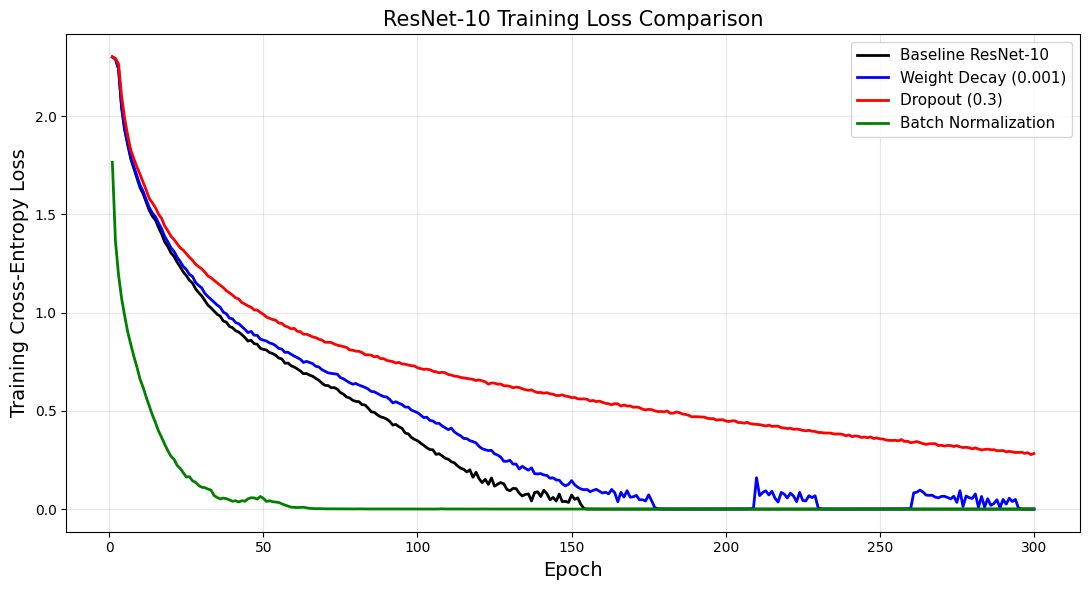

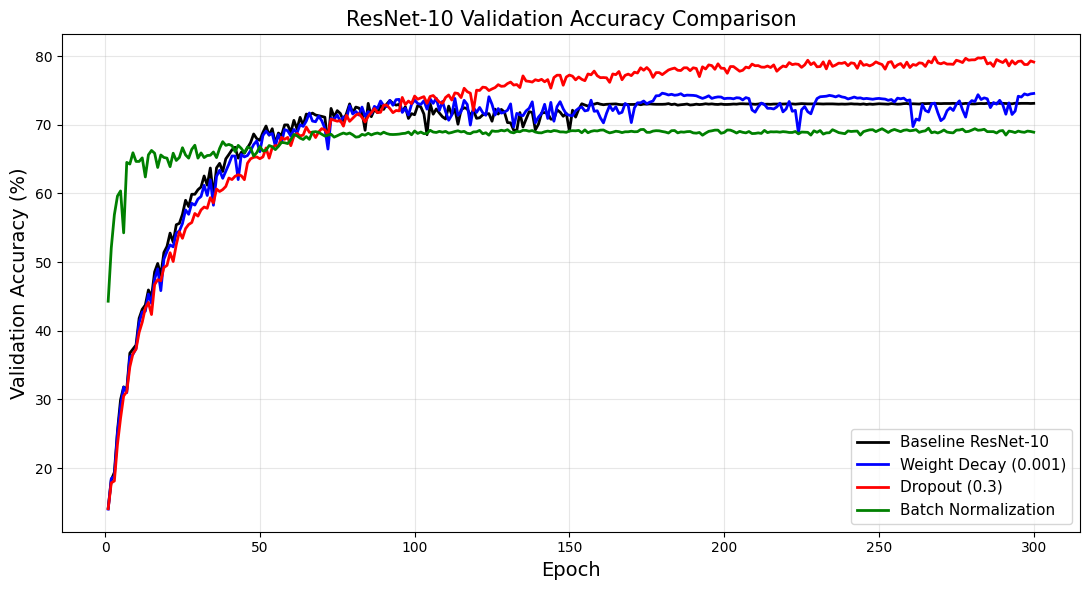

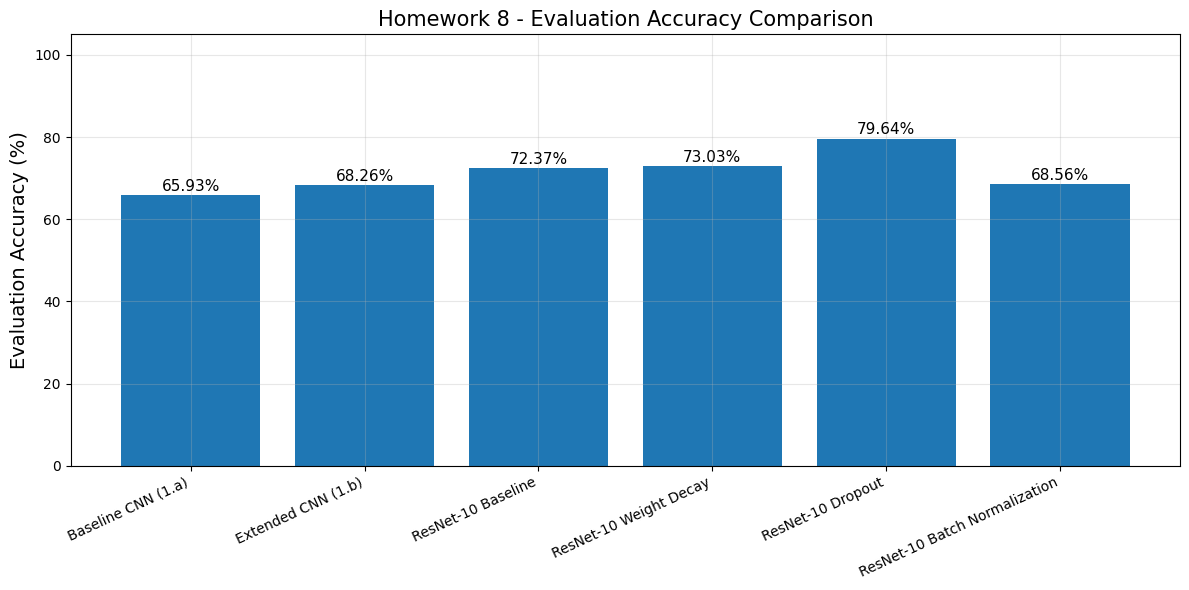


OVERFITTING ANALYSIS


,Model,Training Accuracy (%),Validation Accuracy (%),Evaluation Accuracy (%),Generalization Gap (pp),Minimum Validation Loss,Minimum Validation Loss Epoch,Final Validation Loss,Validation Loss Increase
0,ResNet-10 Baseline,100.000000,73.12,72.37,26.880000,0.784432,79,3.572663,2.788231
1,ResNet-10 Weight Decay,100.000000,74.56,73.03,25.440000,0.774518,89,2.039066,1.264548
2,ResNet-10 Dropout,89.553333,79.14,79.64,10.413333,0.616944,209,0.668187,0.051243
3,ResNet-10 Batch Normalization,100.000000,68.92,68.56,31.080000,0.956250,9,1.977456,1.021205



HOMEWORK 8 - PROBLEM 2 COMPLETED
All four ResNet-10 experiments completed 300 epochs.
All results saved to: /content/drive/MyDrive/ECGR5105_HW8/Problem_2

EXPERIMENT PROGRESS


,Experiment,Completed Epochs,Remaining Epochs,Progress (%),Final Results Saved
0,ResNet-10 Baseline,300,0,100.0,True
1,ResNet-10 Weight Decay,300,0,100.0,True
2,ResNet-10 Dropout,300,0,100.0,True
3,ResNet-10 Batch Normalization,300,0,100.0,True


Overall progress: 1200/1200 epochs (100.00%)


In [ ]:
# ==============================================================
# ECGR 5105 - Introduction to Machine Learning
# Homework 8 - Problem 2(a) and Problem 2(b)
#
# CIFAR-10 Classification Using ResNet-10
#
# Problem 2(a):
#     Baseline ResNet-10 with 10 residual blocks
#
# Problem 2(b):
#     1. Weight Decay (lambda = 0.001)
#     2. Dropout (p = 0.3)
#     3. Batch Normalization
#
# Features:
#     Automatic CPU/GPU selection
#     Automatic CPU fallback for recoverable CUDA errors
#     Checkpoint saving after every epoch
#     Automatic resumption from existing checkpoints
#     Continuous training of all four experiments
#     Comparison against completed Problem 1 results
# ==============================================================

import os
import gc
import time
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision

from torch.utils.data import DataLoader, TensorDataset, Subset
from google.colab import drive
from IPython.display import display


# ==============================================================
# 1. USER CONFIGURATION
# ==============================================================

# Hardware options:
#
# "auto" : GPU if available, otherwise CPU
# "gpu"  : Prefer GPU, fallback to CPU
# "cpu"  : Force CPU

DEVICE_MODE = "auto"

# Experiment options:
#
# "all"          : Complete all unfinished experiments
# "auto"         : First unfinished experiment
# "baseline"     : Baseline ResNet-10
# "weight_decay" : ResNet-10 with weight decay
# "dropout"      : ResNet-10 with dropout
# "batch_norm"   : ResNet-10 with batch normalization

EXPERIMENT = "all"

# Required total number of epochs for each model.

EPOCHS = 300

# Complete all remaining epochs in one execution.

EPOCHS_PER_RUN = 300

# Preserve original experimental settings.

SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 0.001
MOMENTUM = 0.9

WEIGHT_DECAY = 0.001
DROPOUT_P = 0.3

CPU_THREADS = min(4, os.cpu_count() or 2)

NUM_WORKERS = 0

RESUME_TRAINING = True

assert DEVICE_MODE in ["auto", "gpu", "cpu"]
assert EPOCHS_PER_RUN > 0


# ==============================================================
# 2. Mount Google Drive
# ==============================================================

if not os.path.isdir("/content/drive/MyDrive"):

    drive.mount(
        "/content/drive",
        timeout_ms=120000
    )

DATA_DIR = "/content/drive/MyDrive/CIFAR10"

OUTPUT_DIR = "/content/drive/MyDrive/ECGR5105_HW8"

PROBLEM_2_DIR = os.path.join(
    OUTPUT_DIR,
    "Problem_2"
)

os.makedirs(PROBLEM_2_DIR, exist_ok=True)

if not os.path.isdir(
    os.path.join(DATA_DIR, "cifar-10-batches-py")
):

    raise FileNotFoundError(
        f"CIFAR-10 dataset not found in {DATA_DIR}"
    )


# ==============================================================
# 3. Define Experiments
# ==============================================================

EXPERIMENTS = {

    "baseline": {
        "name": "ResNet-10 Baseline",
        "weight_decay": 0.0,
        "dropout": 0.0,
        "batch_norm": False,
        "folder": "Problem_2a_Baseline"
    },

    "weight_decay": {
        "name": "ResNet-10 Weight Decay",
        "weight_decay": WEIGHT_DECAY,
        "dropout": 0.0,
        "batch_norm": False,
        "folder": "Problem_2b_Weight_Decay"
    },

    "dropout": {
        "name": "ResNet-10 Dropout",
        "weight_decay": 0.0,
        "dropout": DROPOUT_P,
        "batch_norm": False,
        "folder": "Problem_2b_Dropout"
    },

    "batch_norm": {
        "name": "ResNet-10 Batch Normalization",
        "weight_decay": 0.0,
        "dropout": 0.0,
        "batch_norm": True,
        "folder": "Problem_2b_Batch_Normalization"
    }

}

EXPERIMENT_ORDER = [
    "baseline",
    "weight_decay",
    "dropout",
    "batch_norm"
]

assert EXPERIMENT in (
    ["auto", "all"] + EXPERIMENT_ORDER
)

for config in EXPERIMENTS.values():

    os.makedirs(
        os.path.join(
            PROBLEM_2_DIR,
            config["folder"]
        ),
        exist_ok=True
    )


def experiment_dir(experiment_key):

    return os.path.join(
        PROBLEM_2_DIR,
        EXPERIMENTS[experiment_key]["folder"]
    )


def checkpoint_path(experiment_key):

    return os.path.join(
        experiment_dir(experiment_key),
        "checkpoint.pth"
    )


def results_path(experiment_key):

    return os.path.join(
        experiment_dir(experiment_key),
        "final_results.json"
    )


# ==============================================================
# 4. CPU/GPU Selection
# ==============================================================

def select_device():

    if DEVICE_MODE == "cpu":

        print("CPU mode selected.")

        return torch.device("cpu")

    try:

        if torch.cuda.is_available():

            # Check if CUDA is actually operational.

            test_tensor = torch.zeros(
                1,
                device="cuda"
            )

            torch.cuda.synchronize()

            del test_tensor

            print(
                "GPU detected:",
                torch.cuda.get_device_name(0)
            )

            return torch.device("cuda")

        print(
            "GPU unavailable. Automatically using CPU."
        )

    except (RuntimeError, AssertionError) as error:

        print("GPU initialization failed.")
        print(error)
        print("Switching to CPU.")

    return torch.device("cpu")


def hardware_name(device):

    if device.type == "cuda":

        return torch.cuda.get_device_name(
            device.index or 0
        )

    return "CPU"


def synchronize_device(device):

    if device.type == "cuda":

        torch.cuda.synchronize()


def set_seed(seed, device):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if device.type == "cuda":

        torch.cuda.manual_seed_all(seed)


torch.set_num_threads(CPU_THREADS)

device = select_device()

if device.type == "cuda":

    torch.backends.cudnn.benchmark = True

set_seed(SEED, device)

print("\n" + "=" * 75)
print("HOMEWORK 8 - PROBLEM 2")
print("=" * 75)

print("Device:", device)
print("Hardware:", hardware_name(device))
print("Experiment:", EXPERIMENT)
print("Total epochs:", EPOCHS)
print("Epochs per execution:", EPOCHS_PER_RUN)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Momentum:", MOMENTUM)
print("CPU threads:", CPU_THREADS)
print("Dataset directory:", DATA_DIR)
print("Output directory:", PROBLEM_2_DIR)


# ==============================================================
# 5. Load Existing CIFAR-10 Dataset
# ==============================================================

print("\nLoading CIFAR-10 from Google Drive...")

raw_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False
)

raw_test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=False
)


def preprocess_dataset(dataset):

    images = torch.from_numpy(dataset.data)

    # Convert NHWC to NCHW.

    images = images.permute(
        0, 3, 1, 2
    ).contiguous()

    # Convert to floating point.

    images = images.float()

    # Normalize exactly as in Problem 1.

    images.div_(255.0)

    images.sub_(0.5).div_(0.5)

    labels = torch.tensor(
        dataset.targets,
        dtype=torch.long
    )

    return TensorDataset(
        images,
        labels
    )


class_names = raw_train_dataset.classes

full_train_dataset = preprocess_dataset(
    raw_train_dataset
)

test_dataset = preprocess_dataset(
    raw_test_dataset
)

del raw_train_dataset
del raw_test_dataset

gc.collect()

# Preserve the same training and validation split
# used in Problem 1 and the previous Problem 2 run.

split_generator = torch.Generator().manual_seed(
    SEED
)

indices = torch.randperm(
    50000,
    generator=split_generator
).tolist()

train_indices = indices[:45000]

val_indices = indices[45000:]

train_dataset = Subset(
    full_train_dataset,
    train_indices
)

val_dataset = Subset(
    full_train_dataset,
    val_indices
)

print("\nDataset loaded successfully.")

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))
print("Number of classes:", len(class_names))
print("Classes:", class_names)

print("Dataset preprocessed and stored in RAM.")


# ==============================================================
# 6. Residual Block
# ==============================================================

class ResidualBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        stride=1,
        dropout=0.0,
        batch_norm=False
    ):

        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=not batch_norm
        )

        self.conv2 = nn.Conv2d(
            in_channels=out_channels,
            out_channels=out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=not batch_norm
        )

        # Batch normalization is used only
        # in the batch normalization experiment.

        self.bn1 = (
            nn.BatchNorm2d(out_channels)
            if batch_norm
            else nn.Identity()
        )

        self.bn2 = (
            nn.BatchNorm2d(out_channels)
            if batch_norm
            else nn.Identity()
        )

        self.relu = nn.ReLU()

        # Dropout is used only in the dropout experiment.

        self.dropout = (
            nn.Dropout(p=dropout)
            if dropout > 0
            else nn.Identity()
        )

        # Skip connection.
        #
        # Identity mapping when dimensions are unchanged.
        # 1 x 1 projection when dimensions change.

        if (
            stride != 1
            or in_channels != out_channels
        ):

            shortcut_layers = [

                nn.Conv2d(
                    in_channels=in_channels,
                    out_channels=out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=not batch_norm
                )

            ]

            if batch_norm:

                shortcut_layers.append(
                    nn.BatchNorm2d(out_channels)
                )

            self.shortcut = nn.Sequential(
                *shortcut_layers
            )

        else:

            self.shortcut = nn.Identity()


    def forward(self, x):

        identity = self.shortcut(x)

        out = self.conv1(x)

        out = self.bn1(out)

        out = self.relu(out)

        out = self.dropout(out)

        out = self.conv2(out)

        out = self.bn2(out)

        # Residual connection.

        out = out + identity

        out = self.relu(out)

        return out


# ==============================================================
# 7. ResNet-10 Architecture
# ==============================================================

class ResNet10(nn.Module):

    def __init__(
        self,
        num_classes=10,
        dropout=0.0,
        batch_norm=False
    ):

        super().__init__()

        self.in_channels = 16

        self.dropout_p = dropout

        self.use_batch_norm = batch_norm

        # Initial convolution:
        # Input:  3 x 32 x 32
        # Output: 16 x 32 x 32

        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=16,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=not batch_norm
        )

        self.bn1 = (
            nn.BatchNorm2d(16)
            if batch_norm
            else nn.Identity()
        )

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Output after pooling: 16 x 16 x 16

        # Stage 1:
        # 3 residual blocks
        # Output: 16 x 16 x 16

        self.stage1 = self.make_stage(
            out_channels=16,
            num_blocks=3,
            first_stride=1
        )

        # Stage 2:
        # 3 residual blocks
        # Output: 32 x 8 x 8

        self.stage2 = self.make_stage(
            out_channels=32,
            num_blocks=3,
            first_stride=2
        )

        # Stage 3:
        # 4 residual blocks
        # Output: 64 x 4 x 4

        self.stage3 = self.make_stage(
            out_channels=64,
            num_blocks=4,
            first_stride=2
        )

        # Total number of residual blocks:
        # 3 + 3 + 4 = 10

        self.avgpool = nn.AdaptiveAvgPool2d(
            (1, 1)
        )

        self.flatten = nn.Flatten()

        # Final fully connected layer:
        # 64 input features
        # 10 CIFAR-10 output classes

        self.fc = nn.Linear(
            64,
            num_classes
        )


    def make_stage(
        self,
        out_channels,
        num_blocks,
        first_stride
    ):

        layers = []

        for block_index in range(num_blocks):

            stride = (
                first_stride
                if block_index == 0
                else 1
            )

            layers.append(

                ResidualBlock(
                    in_channels=self.in_channels,
                    out_channels=out_channels,
                    stride=stride,
                    dropout=self.dropout_p,
                    batch_norm=self.use_batch_norm
                )

            )

            self.in_channels = out_channels

        return nn.Sequential(*layers)


    def forward(self, x):

        x = self.conv1(x)

        x = self.bn1(x)

        x = self.relu(x)

        x = self.pool(x)

        x = self.stage1(x)

        x = self.stage2(x)

        x = self.stage3(x)

        x = self.avgpool(x)

        x = self.flatten(x)

        x = self.fc(x)

        return x


# ==============================================================
# 8. Calculate Model Size
# ==============================================================

def count_parameters(model):

    return sum(

        parameter.numel()

        for parameter in model.parameters()

        if parameter.requires_grad

    )


def model_size_mib(model):

    total_bytes = sum(

        parameter.numel()
        * parameter.element_size()

        for parameter in model.parameters()

    )

    return total_bytes / (1024 ** 2)


def count_residual_blocks(model):

    return sum(

        isinstance(module, ResidualBlock)

        for module in model.modules()

    )


# Verify that the architecture has not changed.

verification_model = ResNet10()

with torch.no_grad():

    dummy_input = torch.zeros(
        2, 3, 32, 32
    )

    dummy_output = verification_model(
        dummy_input
    )

assert dummy_output.shape == (2, 10)

assert count_residual_blocks(
    verification_model
) == 10

assert count_parameters(
    verification_model
) == 345546

print("\nResNet-10 architecture verified.")

print(
    "Residual blocks:",
    count_residual_blocks(verification_model)
)

print(
    "Baseline parameters:",
    count_parameters(verification_model)
)

print(
    "Output dimensions:",
    dummy_output.shape
)

del verification_model
del dummy_input
del dummy_output


# ==============================================================
# 9. Create DataLoaders
# ==============================================================

def create_loader(
    dataset,
    device,
    shuffle=False,
    seed=SEED
):

    generator = torch.Generator().manual_seed(
        seed
    )

    return DataLoader(

        dataset,

        batch_size=BATCH_SIZE,

        shuffle=shuffle,

        generator=generator,

        num_workers=NUM_WORKERS,

        pin_memory=device.type == "cuda",

        persistent_workers=NUM_WORKERS > 0

    )


# ==============================================================
# 10. Evaluation Function
# ==============================================================

def evaluate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0.0

    correct = 0

    total = 0

    with torch.inference_mode():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=device.type == "cuda"
            )

            labels = labels.to(
                device,
                non_blocking=device.type == "cuda"
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            total_loss += (
                loss.item() * labels.size(0)
            )

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    average_loss = total_loss / total

    accuracy = 100.0 * correct / total

    return average_loss, accuracy


# ==============================================================
# 11. Checkpoint Functions
# ==============================================================

def load_checkpoint(experiment_key):

    path = checkpoint_path(
        experiment_key
    )

    if not os.path.exists(path):

        return None

    # Load only checkpoints created by your own notebook.

    return torch.load(

        path,

        map_location="cpu",

        weights_only=False

    )


def completed_epochs(experiment_key):

    checkpoint = load_checkpoint(
        experiment_key
    )

    if checkpoint is None:

        return 0

    return int(
        checkpoint["epoch"] + 1
    )


def save_checkpoint(
    checkpoint,
    experiment_key
):

    path = checkpoint_path(
        experiment_key
    )

    temporary_path = path + ".tmp"

    torch.save(

        checkpoint,

        temporary_path

    )

    os.replace(
        temporary_path,
        path
    )


def save_json(data, path):

    temporary_path = path + ".tmp"

    with open(temporary_path, "w") as file:

        json.dump(
            data,
            file,
            indent=4
        )

    os.replace(
        temporary_path,
        path
    )


def save_training_history(
    history,
    experiment_key
):

    history_df = pd.DataFrame(history)

    history_df.insert(

        0,

        "Epoch",

        np.arange(
            1,
            len(history_df) + 1
        )

    )

    history_df.to_csv(

        os.path.join(
            experiment_dir(experiment_key),
            "training_history.csv"
        ),

        index=False

    )


# ==============================================================
# 12. Check Existing Training Progress
# ==============================================================

def show_progress():

    progress = []

    for key in EXPERIMENT_ORDER:

        completed = completed_epochs(key)

        progress.append({

            "Experiment":
                EXPERIMENTS[key]["name"],

            "Completed Epochs":
                completed,

            "Remaining Epochs":
                max(0, EPOCHS - completed),

            "Progress (%)":
                100.0 * completed / EPOCHS,

            "Final Results Saved":
                os.path.exists(
                    results_path(key)
                )

        })

    progress_df = pd.DataFrame(progress)

    total_completed = int(
        progress_df["Completed Epochs"].sum()
    )

    total_required = (
        EPOCHS * len(EXPERIMENT_ORDER)
    )

    print("\n" + "=" * 75)
    print("EXPERIMENT PROGRESS")
    print("=" * 75)

    display(progress_df.round(2))

    print(
        f"Overall progress: "
        f"{total_completed}/{total_required} epochs "
        f"({100 * total_completed / total_required:.2f}%)"
    )

    progress_df.to_csv(

        os.path.join(
            PROBLEM_2_DIR,
            "training_progress.csv"
        ),

        index=False

    )


show_progress()


# ==============================================================
# 13. Main Training Function
# ==============================================================

def train_experiment(
    experiment_key,
    device,
    target_epoch
):

    config = EXPERIMENTS[
        experiment_key
    ]

    model_name = config["name"]

    save_dir = experiment_dir(
        experiment_key
    )

    current_hardware = hardware_name(
        device
    )

    set_seed(SEED, device)

    # Independently initialize each experiment.

    model = ResNet10(

        num_classes=10,

        dropout=config["dropout"],

        batch_norm=config["batch_norm"]

    ).to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(

        model.parameters(),

        lr=LEARNING_RATE,

        momentum=MOMENTUM,

        weight_decay=config["weight_decay"]

    )

    # IMPORTANT:
    # Do not change this configuration.
    # It must match your previous saved checkpoints.

    configuration = {

        "architecture":
            "ResNet10_16_32_64_3_3_4_v1",

        "experiment":
            experiment_key,

        "total_epochs":
            EPOCHS,

        "batch_size":
            BATCH_SIZE,

        "learning_rate":
            LEARNING_RATE,

        "momentum":
            MOMENTUM,

        "weight_decay":
            config["weight_decay"],

        "dropout":
            config["dropout"],

        "batch_norm":
            config["batch_norm"],

        "seed":
            SEED

    }

    history = {

        "train_loss": [],

        "train_accuracy": [],

        "val_loss": [],

        "val_accuracy": [],

        "epoch_time": [],

        "hardware": []

    }

    start_epoch = 0

    total_training_time = 0.0

    # ----------------------------------------------------------
    # Resume existing training
    # ----------------------------------------------------------

    checkpoint = (

        load_checkpoint(experiment_key)

        if RESUME_TRAINING

        else None

    )

    if checkpoint is not None:

        if (
            checkpoint["configuration"]
            != configuration
        ):

            raise ValueError(

                "Checkpoint configuration mismatch. "
                "Do not delete or overwrite your existing "
                "checkpoint. Check the model configuration."

            )

        model.load_state_dict(

            checkpoint["model_state_dict"]

        )

        optimizer.load_state_dict(

            checkpoint["optimizer_state_dict"]

        )

        # Move optimizer state to the current device.

        for state in optimizer.state.values():

            for key, value in state.items():

                if torch.is_tensor(value):

                    state[key] = value.to(
                        device
                    )

        start_epoch = (

            checkpoint["epoch"] + 1

        )

        history = checkpoint["history"]

        total_training_time = checkpoint[
            "total_training_time"
        ]

        print(
            f"\nCheckpoint loaded: {model_name}"
        )

        print(
            "Completed epochs:",
            start_epoch
        )

        print(
            "Remaining epochs:",
            EPOCHS - start_epoch
        )

        print(
            "Previous training time:",
            f"{total_training_time / 60:.2f} min"
        )

        del checkpoint

    elif os.path.exists(
        results_path(experiment_key)
    ):

        raise RuntimeError(

            "Final results exist but the checkpoint "
            "is missing. Check the saved files before "
            "retraining."

        )

    # ----------------------------------------------------------
    # Skip already completed experiments
    # ----------------------------------------------------------

    if (

        start_epoch >= EPOCHS

        and os.path.exists(
            results_path(experiment_key)
        )

    ):

        print(
            f"\n{model_name} already completed."
        )

        with open(

            results_path(experiment_key),

            "r"

        ) as file:

            return json.load(file)

    parameters = count_parameters(model)

    size_mib = model_size_mib(model)

    print("\n" + "=" * 75)
    print("MODEL:", model_name)
    print("=" * 75)

    print("Hardware:", current_hardware)

    print(
        "Residual blocks:",
        count_residual_blocks(model)
    )

    print(
        "Trainable parameters:",
        f"{parameters:,}"
    )

    print(
        "Model size:",
        f"{size_mib:.6f} MiB"
    )

    print(
        "Weight decay:",
        config["weight_decay"]
    )

    print(
        "Dropout:",
        config["dropout"]
    )

    print(
        "Batch normalization:",
        config["batch_norm"]
    )

    target_epoch = min(
        target_epoch,
        EPOCHS
    )

    if start_epoch < target_epoch:

        print(

            f"Training epochs "
            f"{start_epoch + 1} to "
            f"{target_epoch}"

        )

    val_loader = create_loader(

        val_dataset,

        device,

        shuffle=False

    )

    # ----------------------------------------------------------
    # Training loop
    # ----------------------------------------------------------

    for epoch in range(
        start_epoch,
        target_epoch
    ):

        # Preserve epoch-specific random seeds
        # across interruptions.

        set_seed(
            SEED + epoch,
            device
        )

        train_loader = create_loader(

            train_dataset,

            device,

            shuffle=True,

            seed=SEED + epoch

        )

        model.train()

        running_loss = 0.0

        correct = 0

        total = 0

        synchronize_device(device)

        epoch_start = time.perf_counter()

        for images, labels in train_loader:

            images = images.to(

                device,

                non_blocking=device.type == "cuda"

            )

            labels = labels.to(

                device,

                non_blocking=device.type == "cuda"

            )

            # Clear previous gradients.

            optimizer.zero_grad(
                set_to_none=True
            )

            # Forward propagation.

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            # Backpropagation.

            loss.backward()

            # Update parameters.

            optimizer.step()

            # Training statistics.

            running_loss += (

                loss.item() * labels.size(0)

            )

            predictions = outputs.argmax(
                dim=1
            )

            correct += (

                predictions == labels

            ).sum().item()

            total += labels.size(0)

        synchronize_device(device)

        epoch_time = (

            time.perf_counter() - epoch_start

        )

        total_training_time += epoch_time

        train_loss = running_loss / total

        train_accuracy = (

            100.0 * correct / total

        )

        # ------------------------------------------------------
        # Validation
        # ------------------------------------------------------

        val_loss, val_accuracy = evaluate(

            model,

            val_loader,

            criterion,

            device

        )

        history["train_loss"].append(
            train_loss
        )

        history["train_accuracy"].append(
            train_accuracy
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_accuracy"].append(
            val_accuracy
        )

        history["epoch_time"].append(
            epoch_time
        )

        history["hardware"].append(
            current_hardware
        )

        # ------------------------------------------------------
        # Save checkpoint after every completed epoch
        # ------------------------------------------------------

        checkpoint = {

            "epoch":
                epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "history":
                history,

            "total_training_time":
                total_training_time,

            "configuration":
                configuration

        }

        save_checkpoint(

            checkpoint,

            experiment_key

        )

        save_training_history(

            history,

            experiment_key

        )

        del checkpoint

        # ------------------------------------------------------
        # Estimate remaining training time
        # ------------------------------------------------------

        remaining_epochs = (

            EPOCHS - (epoch + 1)

        )

        # Use the mean of up to the five most recent epochs
        # on the current hardware.

        recent_times = [

            duration

            for duration, hardware in zip(

                history["epoch_time"],
                history["hardware"]

            )

            if hardware == current_hardware

        ][-5:]

        average_epoch_time = float(
            np.mean(recent_times)
        )

        remaining_minutes = (

            remaining_epochs
            * average_epoch_time / 60

        )

        print(

            f"Epoch [{epoch + 1:3d}/{EPOCHS}] | "

            f"Train Loss: {train_loss:.4f} | "

            f"Train Acc: {train_accuracy:.2f}% | "

            f"Val Loss: {val_loss:.4f} | "

            f"Val Acc: {val_accuracy:.2f}% | "

            f"Time: {epoch_time:.2f}s | "

            f"Remaining: "
            f"{remaining_minutes:.1f}min | "

            f"{current_hardware}",

            flush=True

        )

    # ----------------------------------------------------------
    # Stop safely if a smaller training block was selected
    # ----------------------------------------------------------

    trained_epochs = len(
        history["train_loss"]
    )

    if trained_epochs < EPOCHS:

        print("\n" + "=" * 75)
        print("TRAINING BLOCK COMPLETED")
        print("=" * 75)

        print("Model:", model_name)

        print(

            f"Progress: "
            f"{trained_epochs}/{EPOCHS} epochs"

        )

        print(

            f"Remaining epochs: "
            f"{EPOCHS - trained_epochs}"

        )

        print("Checkpoint saved successfully.")

        print(
            "Rerun this cell to continue training."
        )

        return None

    # ----------------------------------------------------------
    # Final evaluation after 300 epochs
    # ----------------------------------------------------------

    print(

        "\nEvaluating final model "
        "on the test dataset..."

    )

    test_loader = create_loader(

        test_dataset,

        device,

        shuffle=False

    )

    test_loss, test_accuracy = evaluate(

        model,

        test_loader,

        criterion,

        device

    )

    hardware_used = list(

        dict.fromkeys(
            history["hardware"]
        )

    )

    # ----------------------------------------------------------
    # Calculate CPU/GPU training time breakdown
    # ----------------------------------------------------------

    hardware_summary = {}

    for hardware, seconds in zip(

        history["hardware"],

        history["epoch_time"]

    ):

        if hardware not in hardware_summary:

            hardware_summary[hardware] = {

                "Epochs": 0,

                "Training Time (s)": 0.0

            }

        hardware_summary[hardware][
            "Epochs"
        ] += 1

        hardware_summary[hardware][
            "Training Time (s)"
        ] += float(seconds)

    results = {

        "Model":
            model_name,

        "Epochs":
            EPOCHS,

        "Residual Blocks":
            count_residual_blocks(model),

        "GPU":
            ", ".join(hardware_used),

        "Evaluation Device":
            current_hardware,

        "Weight Decay":
            config["weight_decay"],

        "Dropout":
            config["dropout"],

        "Batch Normalization":
            config["batch_norm"],

        "Training Time (s)":
            total_training_time,

        "Training Time (min)":
            total_training_time / 60,

        "Training Time per Epoch (s)":
            total_training_time / EPOCHS,

        "Training Loss":
            history["train_loss"][-1],

        "Training Accuracy (%)":
            history["train_accuracy"][-1],

        "Validation Loss":
            history["val_loss"][-1],

        "Validation Accuracy (%)":
            history["val_accuracy"][-1],

        "Test Loss":
            test_loss,

        "Evaluation Accuracy (%)":
            test_accuracy,

        "Parameters":
            parameters,

        "Model Size (MiB)":
            size_mib,

        "Hardware Breakdown":
            hardware_summary

    }

    # ----------------------------------------------------------
    # Save final trained model
    # ----------------------------------------------------------

    cpu_state_dict = {

        key: value.detach().cpu()

        for key, value
        in model.state_dict().items()

    }

    torch.save(

        cpu_state_dict,

        os.path.join(
            save_dir,
            "final_model.pth"
        )

    )

    save_json(

        results,

        results_path(experiment_key)

    )

    save_training_history(

        history,

        experiment_key

    )

    # ----------------------------------------------------------
    # Display final results
    # ----------------------------------------------------------

    print("\n" + "=" * 75)
    print("FINAL RESULTS:", model_name)
    print("=" * 75)

    for key, value in results.items():

        if isinstance(value, float):

            print(
                f"{key}: {value:.6f}"
            )

        else:

            print(
                f"{key}: {value}"
            )

    return results


# ==============================================================
# 14. Automatic GPU-to-CPU Fallback
# ==============================================================

def is_cuda_error(error):

    message = str(error).lower()

    cuda_error_keywords = [

        "cuda",

        "cudnn",

        "cublas",

        "out of memory",

        "driver shutting down",

        "device unavailable",

        "device is busy",

        "driver version"

    ]

    # A device-side assertion may indicate an invalid
    # model operation or labels, not a hardware problem.

    if "device-side assert" in message:

        return False

    return any(

        keyword in message

        for keyword in cuda_error_keywords

    )


def run_with_fallback(
    experiment_key,
    device
):

    start = completed_epochs(
        experiment_key
    )

    target = min(

        start + EPOCHS_PER_RUN,

        EPOCHS

    )

    try:

        result = train_experiment(

            experiment_key,

            device,

            target

        )

        return result, device

    except RuntimeError as error:

        if (

            device.type != "cuda"

            or not is_cuda_error(error)

        ):

            raise

        print("\n" + "=" * 75)
        print("GPU TRAINING FAILED")
        print("=" * 75)

        print(error)

        print(

            "Switching to CPU and resuming "
            "from the last successfully saved checkpoint."

        )

    # Release failed GPU allocations.

    gc.collect()

    try:

        torch.cuda.empty_cache()

    except RuntimeError:

        pass

    # Switch to CPU.

    device = torch.device("cpu")

    torch.set_num_threads(
        CPU_THREADS
    )

    # Reload the latest checkpoint and finish the
    # remaining epochs on CPU.

    result = train_experiment(

        experiment_key,

        device,

        target

    )

    return result, device


# ==============================================================
# 15. Load Actual Problem 1 Results
# ==============================================================

baseline_cnn_path = os.path.join(

    OUTPUT_DIR,

    "Problem_1a",

    "final_results.json"

)

extended_cnn_path = os.path.join(

    OUTPUT_DIR,

    "Problem_1b",

    "final_results.json"

)

if os.path.exists(baseline_cnn_path):

    with open(

        baseline_cnn_path,

        "r"

    ) as file:

        baseline_cnn_results = json.load(
            file
        )

else:

    # Actual completed Problem 1(a) results.

    baseline_cnn_results = {

        "Model": "Baseline CNN (1.a)",

        "Epochs": 300,

        "GPU": "Tesla T4",

        "Training Time (s)": 2930.830220,

        "Training Time (min)": 48.847170,

        "Training Loss": 0.439738,

        "Training Accuracy (%)": 84.704444,

        "Validation Accuracy (%)": 65.64,

        "Evaluation Accuracy (%)": 65.93,

        "Parameters": 25578,

        "Model Size (MiB)": 0.097572

    }

if os.path.exists(extended_cnn_path):

    with open(

        extended_cnn_path,

        "r"

    ) as file:

        extended_cnn_results = json.load(
            file
        )

else:

    # Actual completed Problem 1(b) results.

    extended_cnn_results = {

        "Model": "Extended CNN (1.b)",

        "Epochs": 300,

        "GPU": "Tesla T4, CPU",

        "Training Time (s)": 4400.107621,

        "Training Time (min)": 73.335127,

        "Training Loss": 0.098686,

        "Training Accuracy (%)": 96.775556,

        "Validation Accuracy (%)": 68.44,

        "Evaluation Accuracy (%)": 68.26,

        "Parameters": 33834,

        "Model Size (MiB)": 0.129066

    }

print("\nProblem 1 results loaded successfully.")


# ==============================================================
# 16. Functions for Loading and Comparing Results
# ==============================================================

comparison_columns = [

    "Model",

    "Epochs",

    "GPU",

    "Training Time (s)",

    "Training Time (min)",

    "Training Loss",

    "Evaluation Accuracy (%)",

    "Parameters",

    "Model Size (MiB)"

]


def load_all_results():

    resnet_results = {}

    resnet_histories = {}

    for key in EXPERIMENT_ORDER:

        path = results_path(key)

        checkpoint = load_checkpoint(key)

        if checkpoint is not None:

            resnet_histories[key] = (
                checkpoint["history"]
            )

            completed = int(
                checkpoint["epoch"] + 1
            )

        else:

            completed = 0

        if (
            os.path.exists(path)
            and completed == EPOCHS
        ):

            with open(path, "r") as file:

                saved_results = json.load(
                    file
                )

            if saved_results["Epochs"] == EPOCHS:

                resnet_results[key] = saved_results

    return resnet_results, resnet_histories


def print_and_save_table(
    dataframe,
    title,
    filename
):

    print("\n" + "=" * 75)
    print(title)
    print("=" * 75)

    display(
        dataframe.round(6)
    )

    dataframe.to_csv(

        os.path.join(
            PROBLEM_2_DIR,
            filename
        ),

        index=False

    )


def compare_models(
    reference,
    candidate
):

    return {

        "Reference Model":
            reference["Model"],

        "Model":
            candidate["Model"],

        "Accuracy Difference (pp)":

            candidate["Evaluation Accuracy (%)"]
            - reference["Evaluation Accuracy (%)"],

        "Training Loss Difference":

            candidate["Training Loss"]
            - reference["Training Loss"],

        "Training Time Change (%)":

            100.0 * (

                candidate["Training Time (s)"]
                - reference["Training Time (s)"]

            ) / reference["Training Time (s)"],

        "Parameter Change (%)":

            100.0 * (

                candidate["Parameters"]
                - reference["Parameters"]

            ) / reference["Parameters"],

        "Reference Hardware":
            reference["GPU"],

        "Training Hardware":
            candidate["GPU"]

    }


# ==============================================================
# 17. Save Comparison Tables
# ==============================================================

def generate_comparisons(
    resnet_results
):

    # ----------------------------------------------------------
    # Problem 2(a):
    # Baseline ResNet-10 versus Extended CNN (1.b)
    # ----------------------------------------------------------

    if "baseline" in resnet_results:

        baseline_resnet = resnet_results[
            "baseline"
        ]

        comparison_2a = pd.DataFrame([

            extended_cnn_results,

            baseline_resnet

        ])[comparison_columns]

        print_and_save_table(

            comparison_2a,

            "PROBLEM 2(a): RESNET-10 VS EXTENDED CNN",

            "Problem_2a_Comparison.csv"

        )

        analysis_2a = compare_models(

            extended_cnn_results,

            baseline_resnet

        )

        print(

            "Accuracy difference:",

            f"{analysis_2a['Accuracy Difference (pp)']:+.2f} pp"

        )

        print(

            "Parameter change:",

            f"{analysis_2a['Parameter Change (%)']:+.2f}%"

        )

        print(

            "Training time change:",

            f"{analysis_2a['Training Time Change (%)']:+.2f}%"

        )

        save_json(

            analysis_2a,

            os.path.join(

                PROBLEM_2_DIR,

                "Problem_2a_Analysis.json"

            )

        )

        if (

            baseline_resnet["GPU"]

            != extended_cnn_results["GPU"]

        ):

            print(

                "NOTE: Training hardware differs. "

                "Training time differences cannot be "

                "attributed solely to model architecture."

            )

    # ----------------------------------------------------------
    # Problem 2(b):
    # Compare independent regularization experiments
    # against Problem 1(a) and baseline ResNet.
    # ----------------------------------------------------------

    regularization_keys = [

        "weight_decay",

        "dropout",

        "batch_norm"

    ]

    completed_regularization = [

        resnet_results[key]

        for key in regularization_keys

        if key in resnet_results

    ]

    if completed_regularization:

        comparison_rows = [

            baseline_cnn_results

        ]

        if "baseline" in resnet_results:

            comparison_rows.append(

                resnet_results["baseline"]

            )

        comparison_rows.extend(

            completed_regularization

        )

        comparison_2b = pd.DataFrame(

            comparison_rows

        )[comparison_columns]

        print_and_save_table(

            comparison_2b,

            "PROBLEM 2(b): REGULARIZATION COMPARISON",

            "Problem_2b_Comparison.csv"

        )

        regularization_analysis = []

        for result in completed_regularization:

            analysis = {

                "Model":
                    result["Model"],

                "Accuracy Difference vs CNN (pp)":

                    result["Evaluation Accuracy (%)"]

                    - baseline_cnn_results[
                        "Evaluation Accuracy (%)"
                    ],

                "Training Time Change vs CNN (%)":

                    100.0 * (

                        result["Training Time (s)"]

                        - baseline_cnn_results[
                            "Training Time (s)"
                        ]

                    ) / baseline_cnn_results[
                        "Training Time (s)"
                    ],

                "Training Hardware":
                    result["GPU"]

            }

            if "baseline" in resnet_results:

                baseline_resnet = resnet_results[
                    "baseline"
                ]

                analysis[
                    "Accuracy Difference vs Baseline ResNet (pp)"
                ] = (

                    result["Evaluation Accuracy (%)"]

                    - baseline_resnet[
                        "Evaluation Accuracy (%)"
                    ]

                )

                analysis[
                    "Training Loss Difference vs Baseline ResNet"
                ] = (

                    result["Training Loss"]

                    - baseline_resnet["Training Loss"]

                )

                analysis[
                    "Training Time Change vs Baseline ResNet (%)"
                ] = 100.0 * (

                    result["Training Time (s)"]

                    - baseline_resnet[
                        "Training Time (s)"
                    ]

                ) / baseline_resnet[
                    "Training Time (s)"
                ]

            regularization_analysis.append(
                analysis
            )

        analysis_df = pd.DataFrame(
            regularization_analysis
        )

        print_and_save_table(

            analysis_df,

            "PROBLEM 2(b): REGULARIZATION ANALYSIS",

            "Problem_2b_Regularization_Analysis.csv"

        )

    # ----------------------------------------------------------
    # Overall comparison
    # ----------------------------------------------------------

    all_results = [

        baseline_cnn_results,

        extended_cnn_results

    ]

    for key in EXPERIMENT_ORDER:

        if key in resnet_results:

            all_results.append(

                resnet_results[key]

            )

    all_comparison = pd.DataFrame(

        all_results

    )[comparison_columns]

    print_and_save_table(

        all_comparison,

        "OVERALL HOMEWORK 8 MODEL COMPARISON",

        "Homework_8_Model_Comparison.csv"

    )

    return all_results


# ==============================================================
# 18. Generate and Save Plots
# ==============================================================

plot_labels = {

    "baseline":
        "Baseline ResNet-10",

    "weight_decay":
        "Weight Decay (0.001)",

    "dropout":
        "Dropout (0.3)",

    "batch_norm":
        "Batch Normalization"

}

plot_colors = {

    "baseline": "black",

    "weight_decay": "blue",

    "dropout": "red",

    "batch_norm": "green"

}


def save_plot(path, show=False):

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(

        path,

        dpi=300,

        bbox_inches="tight"

    )

    if show:

        plt.show()

    plt.close()


def generate_plots(
    resnet_results,
    resnet_histories,
    all_results,
    show=False
):

    if not resnet_histories:

        return

    # ----------------------------------------------------------
    # Training loss comparison
    # ----------------------------------------------------------

    plt.figure(figsize=(11, 6))

    for key, history in resnet_histories.items():

        epochs = np.arange(

            1,

            len(history["train_loss"]) + 1

        )

        plt.plot(

            epochs,

            history["train_loss"],

            label=plot_labels[key],

            color=plot_colors[key],

            linewidth=2

        )

    plt.xlabel("Epoch", fontsize=14)

    plt.ylabel(
        "Training Cross-Entropy Loss",
        fontsize=14
    )

    plt.title(
        "ResNet-10 Training Loss Comparison",
        fontsize=15
    )

    plt.legend(fontsize=11)

    save_plot(

        os.path.join(

            PROBLEM_2_DIR,

            "Problem_2_Training_Loss.png"

        ),

        show=show

    )

    # ----------------------------------------------------------
    # Validation accuracy comparison
    # ----------------------------------------------------------

    plt.figure(figsize=(11, 6))

    for key, history in resnet_histories.items():

        epochs = np.arange(

            1,

            len(history["val_accuracy"]) + 1

        )

        plt.plot(

            epochs,

            history["val_accuracy"],

            label=plot_labels[key],

            color=plot_colors[key],

            linewidth=2

        )

    plt.xlabel("Epoch", fontsize=14)

    plt.ylabel(
        "Validation Accuracy (%)",
        fontsize=14
    )

    plt.title(
        "ResNet-10 Validation Accuracy Comparison",
        fontsize=15
    )

    plt.legend(fontsize=11)

    save_plot(

        os.path.join(

            PROBLEM_2_DIR,

            "Problem_2_Validation_Accuracy.png"

        ),

        show=show

    )

    # ----------------------------------------------------------
    # Individual training and validation curves
    # ----------------------------------------------------------

    for key, history in resnet_histories.items():

        epochs = np.arange(

            1,

            len(history["train_loss"]) + 1

        )

        save_dir = experiment_dir(key)

        # Loss curves.

        plt.figure(figsize=(9, 5))

        plt.plot(

            epochs,

            history["train_loss"],

            label="Training Loss",

            linewidth=2

        )

        plt.plot(

            epochs,

            history["val_loss"],

            label="Validation Loss",

            linestyle="--",

            linewidth=2

        )

        plt.xlabel("Epoch", fontsize=13)

        plt.ylabel(
            "Cross-Entropy Loss",
            fontsize=13
        )

        plt.title(
            plot_labels[key] + " - Loss",
            fontsize=14
        )

        plt.legend()

        save_plot(

            os.path.join(
                save_dir,
                "loss_curve.png"
            )

        )

        # Accuracy curves.

        plt.figure(figsize=(9, 5))

        plt.plot(

            epochs,

            history["train_accuracy"],

            label="Training Accuracy",

            linewidth=2

        )

        plt.plot(

            epochs,

            history["val_accuracy"],

            label="Validation Accuracy",

            linestyle="--",

            linewidth=2

        )

        plt.xlabel("Epoch", fontsize=13)

        plt.ylabel("Accuracy (%)", fontsize=13)

        plt.title(
            plot_labels[key] + " - Accuracy",
            fontsize=14
        )

        plt.legend()

        save_plot(

            os.path.join(
                save_dir,
                "accuracy_curve.png"
            )

        )

    # ----------------------------------------------------------
    # Final evaluation accuracy comparison
    # ----------------------------------------------------------

    if resnet_results:

        labels = [

            result["Model"]

            for result in all_results

        ]

        accuracies = [

            result["Evaluation Accuracy (%)"]

            for result in all_results

        ]

        plt.figure(figsize=(12, 6))

        bars = plt.bar(

            labels,

            accuracies

        )

        for bar, accuracy in zip(

            bars,

            accuracies

        ):

            plt.text(

                bar.get_x() + bar.get_width() / 2,

                accuracy + 1,

                f"{accuracy:.2f}%",

                ha="center",

                fontsize=11

            )

        plt.ylabel(
            "Evaluation Accuracy (%)",
            fontsize=14
        )

        plt.title(
            "Homework 8 - Evaluation Accuracy Comparison",
            fontsize=15
        )

        plt.ylim(0, 105)

        plt.xticks(
            rotation=25,
            ha="right"
        )

        save_plot(

            os.path.join(

                PROBLEM_2_DIR,

                "Homework_8_Accuracy_Comparison.png"

            ),

            show=show

        )


# ==============================================================
# 19. Overfitting Analysis
# ==============================================================

def generate_overfitting_analysis(
    resnet_results,
    resnet_histories
):

    overfitting_results = []

    for key, results in resnet_results.items():

        history = resnet_histories.get(
            key
        )

        if history is None:

            continue

        train_accuracy = results[
            "Training Accuracy (%)"
        ]

        val_accuracy = results[
            "Validation Accuracy (%)"
        ]

        generalization_gap = (

            train_accuracy - val_accuracy

        )

        minimum_val_loss = min(

            history["val_loss"]

        )

        final_val_loss = history[
            "val_loss"
        ][-1]

        best_epoch = int(

            np.argmin(
                history["val_loss"]
            ) + 1

        )

        overfitting_results.append({

            "Model":
                results["Model"],

            "Training Accuracy (%)":
                train_accuracy,

            "Validation Accuracy (%)":
                val_accuracy,

            "Evaluation Accuracy (%)":
                results["Evaluation Accuracy (%)"],

            "Generalization Gap (pp)":
                generalization_gap,

            "Minimum Validation Loss":
                minimum_val_loss,

            "Minimum Validation Loss Epoch":
                best_epoch,

            "Final Validation Loss":
                final_val_loss,

            "Validation Loss Increase":
                final_val_loss - minimum_val_loss

        })

    if overfitting_results:

        overfitting_df = pd.DataFrame(

            overfitting_results

        )

        print_and_save_table(

            overfitting_df,

            "OVERFITTING ANALYSIS",

            "Problem_2_Overfitting_Analysis.csv"

        )

    return overfitting_results


# ==============================================================
# 20. Generate and Save Current Summary
# ==============================================================

def update_reports(show=False):

    resnet_results, resnet_histories = (

        load_all_results()

    )

    all_results = generate_comparisons(

        resnet_results

    )

    generate_plots(

        resnet_results,

        resnet_histories,

        all_results,

        show=show

    )

    overfitting_results = (

        generate_overfitting_analysis(

            resnet_results,

            resnet_histories

        )

    )

    summary = {

        "Problem_1a_Baseline_CNN":
            baseline_cnn_results,

        "Problem_1b_Extended_CNN":
            extended_cnn_results,

        "Problem_2_Completed_Experiments":
            resnet_results,

        "Overfitting_Analysis":
            overfitting_results,

        "Training_Time_Definition":

            "Training time includes completed training epochs "
            "and excludes validation, testing, checkpoint saving, "
            "and incomplete epochs lost during interruptions.",

        "Training_Time_Limitation":

            "CPU and GPU training times may not be directly "
            "comparable because the hardware differs. "
            "The preprocessing pipeline also differs "
            "between Problems 1 and 2.",

        "All_Experiments_Completed":

            len(resnet_results) == len(EXPERIMENT_ORDER)

    }

    save_json(

        summary,

        os.path.join(

            PROBLEM_2_DIR,

            "Problem_2_Final_Summary.json"

        )

    )

    return resnet_results


# ==============================================================
# 21. Select Unfinished Experiments
# ==============================================================

unfinished_experiments = [

    key

    for key in EXPERIMENT_ORDER

    if (

        completed_epochs(key) < EPOCHS

        or not os.path.exists(
            results_path(key)
        )

    )

]

if EXPERIMENT == "auto":

    selected_experiments = (

        unfinished_experiments[:1]

    )

elif EXPERIMENT == "all":

    selected_experiments = (

        unfinished_experiments

    )

else:

    selected_experiments = [

        EXPERIMENT

    ]


print("\n" + "=" * 75)
print("EXPERIMENTS TO RUN")
print("=" * 75)

for index, key in enumerate(
    selected_experiments,
    start=1
):

    completed = completed_epochs(key)

    print(

        f"{index}. {EXPERIMENTS[key]['name']} | "

        f"Completed: {completed}/{EPOCHS} | "

        f"Remaining: {EPOCHS - completed}"

    )

if not selected_experiments:

    print("All ResNet-10 experiments already completed.")


# ==============================================================
# 22. Execute All Selected Experiments
# ==============================================================

for experiment_key in selected_experiments:

    print("\n" + "=" * 75)

    print(

        "SELECTED EXPERIMENT:",

        EXPERIMENTS[
            experiment_key
        ]["name"]

    )

    print("=" * 75)

    result, device = run_with_fallback(

        experiment_key,

        device

    )

    # Release memory before the next experiment.

    gc.collect()

    if device.type == "cuda":

        try:

            torch.cuda.empty_cache()

        except RuntimeError:

            pass

    # Save comparison tables and plots immediately
    # after each experiment or training block.

    show_progress()

    update_reports(show=False)


# ==============================================================
# 23. Final Results and Completion Status
# ==============================================================

resnet_results = update_reports(
    show=True
)

print("\n" + "=" * 75)

if len(resnet_results) == 4:

    print("HOMEWORK 8 - PROBLEM 2 COMPLETED")

    print(

        "All four ResNet-10 experiments "
        "completed 300 epochs."

    )

else:

    print("TRAINING EXECUTION COMPLETED")

    print(

        f"Finished experiments: "

        f"{len(resnet_results)}/4"

    )

    print(

        "Rerun the same code to continue "
        "any unfinished experiments."

    )

print("=" * 75)

print("All results saved to:", PROBLEM_2_DIR)

show_progress()